In [ ]:
pip install openai --upgrade

Note: you may need to restart the kernel to use updated packages.


In [ ]:
# ═══════════════════════════════════════════════════════════════
# FemTech Privacy Thesis — LLM Analysis with GPT-4o-mini
# Tasks: #5 Policy Scoring + #6 Say-Do Gap Index
# ═══════════════════════════════════════════════════════════════

# pip install openai --break-system-packages

import os, json, time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from openai import OpenAI
from tqdm import tqdm

OPENAI_KEY = "YOUR_OPENAI_API_KEY"
client = OpenAI(api_key=OPENAI_KEY)
MODEL  = "gpt-4o-mini"

def ask_gpt(prompt, system="You are a privacy expert.", temperature=0.1, max_tokens=256):
    for attempt in range(4):
        try:
            r = client.chat.completions.create(
                model=MODEL,
                messages=[
                    {"role": "system", "content": system},
                    {"role": "user",   "content": prompt}
                ],
                temperature=temperature,
                max_tokens=max_tokens,
            )
            return r.choices[0].message.content.strip()
        except Exception as e:
            wait = 2 ** attempt
            print(f"  Retry {attempt+1}: {e} — waiting {wait}s")
            time.sleep(wait)
    return None

# Quick connection test
test = ask_gpt("Reply with only: READY", max_tokens=10)
print("GPT-4o-mini connection:", test)


GPT-4o-mini connection: READY


In [ ]:
# ── Fetch privacy policy texts ────────────────────────────────────────────────
import requests
from bs4 import BeautifulSoup

URLS = {
    "Flo":           "https://flo.health/privacy-policy",
    "Clue":          "https://helloclue.com/privacy",
    "Premom":        "https://premom.com/privacy-policy/",
    "NaturalCycles": "https://www.naturalcycles.com/other/legal/privacy",
    "Stardust":      "https://stardust.app/privacy-policy",
}
HEADERS = {"User-Agent": "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36"}

POLICIES = {}
for app, url in URLS.items():
    try:
        r = requests.get(url, headers=HEADERS, timeout=20)
        soup = BeautifulSoup(r.text, "html.parser")
        for tag in soup(["nav","footer","script","style","header","button"]):
            tag.decompose()
        main = soup.find("main") or soup.find("article") or soup.find("body")
        text = main.get_text("\n", strip=True) if main else soup.get_text()
        POLICIES[app] = "\n".join(l for l in text.splitlines() if l.strip())
        print(f"  {app}: {len(POLICIES[app]):,} chars")
    except Exception as e:
        POLICIES[app] = ""
        print(f"  {app}: FAILED ({e})")
    time.sleep(1)

# Manual paste for any empty ones:
# POLICIES["Flo"] = """paste full text here"""
POLICIES["Clue"] = """

English
Clue Privacy Policy
Last updated May 20, 2026

1. How Clue values data privacy
At Clue, we believe that technology and data present a groundbreaking opportunity to empower people to take control of their health. The Clue app gives people the ability to understand what is going on inside of their bodies and minds based on individual tracked health data, providing self-insight and self-advocacy that’s powered by data processing.

We also fully acknowledge the responsibility that comes with being the safekeepers of so much intimate data which is tracked by people using Clue. Which is why we are always striving to achieve the highest standards of privacy and security. Keeping your data safe is at the core of everything we do.

We see it as our job to be clear and transparent so that you can truly understand what we do with your data, even though the digital ecosystem of an app is complex. To provide our service as a health app, we rely on a number of other providers as summarized below to help us.

Please read the whole of this Privacy Policy to understand how we handle your data. We have done our best to make it as clear and comprehensible as possible. If you have any questions, reach out to us at <trust@helloclue.com>.

If you are a US resident, you can read our Supplemental US Privacy Notice here.

2. The types of data we process
We process three types of data in order to provide our services on the Clue app and the helloclue.com website. All of our data is securely stored on servers located in the European Union (EU).

Account data: In order to create your Clue account, we process some of your personal data such as a username, date of birth and email address.

Usage data: In order to provide our services and technically improve performance, we process how you interact with our products using different data points. Such data includes device data, which informs us about the device you use to access our app services (such as device model, name and identifiers, device settings, application identifier, crash information). On our website, we also collect information about your browser (such as browser settings, operating system, system settings). Other usage data includes the IP address provided by your browser or mobile device, which we collect in order to deliver the service to your device. We also use the IP address to determine your approximate location for statistical and analytics purposes, and for regulatory compliance in different countries. We do not collect your precise location.

Health data: In order to provide our service as a health app, we process health data and other sensitive data that you choose to track in the Clue app. Such health data may include your cycle information (e.g. period length, pain, or spotting), and depending on the data you provide, it may also contain other sensitive data about your experiences (e.g. weight, body temperature, hair quality, sexual intercourse). We only process the health data you choose to share with the Clue app via tracking. You may use different methods provided by the app to track your health data in the app. This can include manually entering your data into the app, or importing your data from other integrations or devices supported by Clue (such as Apple Health or fitness trackers).

3. How and why we process your data
Data processing is essential to providing the service of Clue. Whenever you use our services, some personal and non-personal data is collected, stored, and analyzed using internal and third-party tools.

Below are the purposes for which we process your data, and the type of data that’s processed to fulfill each purpose:

3.1 To provide our core service to you
To provide our service, we process the following:

Health data: This is processed whenever you track your health data in the Clue app, either manually or through import integrations, in order to provide our core service as a health tracking app. This includes both your cycle information data and other sensitive data that you choose to track in the Clue app.
Device data, event data, usage data, IP address: This is processed when you use the Clue app or helloclue.com, to understand how you interact with our services and to technically improve performance.
Account data: This is processed when you set up your Clue account in the app or in the website, to enable you to sign in to the Clue app, and additionally to communicate with you on service-related topics. Such communications may include information about your account, essential app updates, or insights and recommendations based on health data you have tracked. These communications can be sent to you via in-app messages, reminders, notifications, or emails.
Please read the following sections to understand which third party services, integrations, and partnerships we use to provide our core service.

3.1.1 Essential third party providers:
We use several third party providers to help us perform our core services.

Amazon Web Services: Clue uses Amazon Web Services EMEA SARL (“AWS”) as our hosting provider to store our data on secure servers. We only use AWS data centers in the European Union. All data stored with AWS is encrypted by Clue.

Braze: Clue uses services operated by Braze, a company based in the United States, to help us facilitate communication with you via in-app messages, push notifications and emails. Such communications may include information about your account, essential app updates, or insights and recommendations based on health data you have tracked. For this purpose Braze processes your email address, name, user identifier, certain tracked health data, and usage data. This data is always treated in a masked, obfuscated (pseudonymized) form.

Braze has ensured an adequate level of data protection by being listed under the EU-US Data Privacy Framework ,and by also entering into an agreement with Clue based on the Standard Contractual Clauses for data transfer between EU countries and non-EU countries (see Section 4). The privacy policy of these services can be found on their respective websites. Data concerning your use of the Clue app is stored on a server in the EU, operated by Braze, Inc.

It is not possible to opt-out of Braze as it is an essential tool that we require in order to provide our services to you. However, you can opt out of certain types of messaging from Braze, as explained in Section 3.6.

Datadog: Clue uses services provided by Datadog Inc. (Datadog), a company based in the United States, to carry out service and infrastructure monitoring and alerting. Datadog helps us monitor the application performance in real time and resolve issues impacting our users quickly. Datadog stores the data on EU servers.

It is not possible to opt-out of Datadog as it is an essential tool that we require in order to provide a functioning Clue app to you.

Firebase Cloud Messaging: The Android Clue app uses Firebase Cloud Messaging (FCM) to send push notifications and alerts to your device. This service is provided by Google Inc. For this purpose Firebase Cloud Messaging requires a "Push Token" to function. This token is a unique identifier linked to a specific device.

It is not possible to opt-out of Firebase as it is an essential tool that we require in order to provide a functioning Clue app to you.

Sparkpost: Clue uses services provided by Message Systems Inc. (“SparkPost”), a company based in the United States, to process names, email addresses and personal information that may be included in transactional emails (such as “I lost my password” or “Verify your Clue account” emails).

It is not possible to opt-out of Sparkpost as it is an essential tool that we require in order to provide a functioning Clue app to you.

Legal basis: The legal basis for processing your account data and usage data for providing our Clue services is Art 6 Sec. 1 lit b) GDPR, and Art 9 Sec.2 lit a) GDPR for your health data.

3.1.2 Integrations to track your data:
In addition to manually tracking your health data in the Clue app, importing data from other sources is supported for the integrations listed below.

Apple Health (iOS): This section is only applicable to users who choose to sync their Apple Health app with the Clue app. Clue will not exchange any personal data with Apple’s Health app unless you specifically approve this. Approval can be given by you in the relevant settings of the Health app or within the Clue app via your Settings. If you have given your approval, Clue may interact with the Health app on your iOS device and read and/or write information between the Clue app and the Health app. This may include a transfer of your personal data to Apple servers located outside the European Union.

You can choose if and to what extent your personal data is exchanged between Clue and the Health app by granting or revoking the relevant permissions in your Health app settings. This can be done at any time. Please refer to the Privacy Information of Apple Health for further information.

Google Health Connect (Android): This section is only applicable to users who choose to sync the Clue app with Google Health Connect. Clue will not exchange any personal data with Health Connect unless you specifically approve this.

Approval can be given by you in the Health Connect app settings on your device or within the Clue app via your Settings. If you have given your approval, Clue may interact with Health Connect on your Android device to read and/or write information between the Clue app and Health Connect. This may include a transfer of your personal data to Google servers, which may be located outside the European Union.

You can choose if and to what extent your personal data is exchanged between Clue and Health Connect by granting or revoking the relevant permissions in your Health Connect settings. This can be done at any time. For more information on how Google handles your data, please refer to the Google Health Connect Privacy Policy.

Wearables integrations: Clue is partnering with certain companies who provide wearable devices to their users (“Wearables Partners”). This section is only applicable to users who sign up to Clue via a Wearables Partner, or who already have a Clue Plus account and have decided to connect their Clue account with their wearable device. Clue will not exchange any personal data with Wearables Partners. If you have connected your Wearables Partner profile with your Clue profile and given permission in your Wearables Partner app settings, the Wearables Partner shares some tracked data with us. We use this for the purpose of providing better data visualization and enhancing your Clue app experience, and for other purposes depending on what you have agreed to in the Clue app’s privacy settings.

You can choose if and to what extent your personal data is exchanged between the Wearables Partner and Clue, by granting or revoking the relevant permissions in your Wearables Partner settings. This can be done at any time. You can read more about this in the respective privacy policies of the Wearables Partners. You can find a list of our Wearables Partners here.

3.1.3 Social logins:
When first creating your Clue account, there are several options on how to sign up. In addition to signing up with your email address, it’s possible to use services provided by Facebook, Apple, or Google.

Facebook Login: Clue uses “Facebook Login” to allow users to sign in to their Clue account with their Facebook credentials. If you use this service, you authorize us to collect your basic profile information from Facebook, such as your name, email address and profile picture. This information is collected by Facebook and is provided to us under the terms of Meta’s Privacy Policy. You can control the data we receive from Facebook in the privacy settings within your Facebook account.

If you signed up to Clue using Facebook,Clue will only exchange with Facebook the types of data you provided to Facebook when creating an account with them (such as name, email address). This may include a transfer of your personal data to Facebook servers located outside the European Union. It is your choice if and to what extent you use the “Facebook Login” service and what information you provide to Facebook. Absolutely no health data will be exchanged with Facebook.

Sign in with Apple: Clue uses “Sign in with Apple” to allow users to create and sign in to their Clue account with their Apple credentials.

If you sign up to Clue using Apple, Clue will exchange certain data with Apple like device data, IP-address, and information you provided to Apple when creating an account with Apple Inc. This may include a transfer of your personal data to Apple servers located outside the European Union. It is your choice if and to what extent you use the “Sign in with Apple” service and what information you provide to Apple. Absolutely no health data will be exchanged with Apple for the purpose of using the “Sign in with Apple” service.

Sign in with Google: Clue uses “Sign in with Google” to allow users to create and sign in their Clue account with their Google credentials. If you use this service, you authorize us to collect your basic information from Google, like your email address. You can manage this any time in your Google account. Please see Google's resources for more details on this.

If you sign up to Clue using Google, Clue will exchange with Google the types of data you provided to Google when creating an account with them (such as name, email address). This may include a transfer of your personal data to Google servers located outside the European Union. It is your choice if and to what extent you use the “Sign in with Google” service and what information you provide to Google. Absolutely no health data will be exchanged with Google.

3.1.4. Partnerships
To allow users from other platforms to sign up to Clue and subscribe to Clue Plus, Clue has partnerships with a number of business partners, including wellbeing applications providers (“Partner”).

This section is only applicable to users who sign up for Clue Plus via a Partner. Clue Plus is part of the service offering of such Partners.

If you choose to sign up for Clue Plus using your Partner subscription, the Partner sends Clue your pseudonymized identifier to us as confirmation that you are a Partner subscriber. Upon receiving this information, Clue will then activate your Clue Plus subscription. Clue shares with Partners whether you have been active in the Clue app. This is done by sending an event, such as ‘Create Record’ to the Partner. The event name depends on the partner, however, at no point does the Partner ever receive any of your tracked health data, nor any event names that would reveal anything about your health. A list of such partnerships can be found on our webpage.

Legal basis: Our legal basis for processing the above mentioned data is Art. 6 b) General Data Protection Regulation (GDPR), which means that we use it to perform the contract that you have entered into with Clue, via the Partner. We also process your Clue account data and usage data on the legal basis of Art 6 Sec.1 lit b) GDPR to provide our services to you. The processing of health data to provide our service to you is based on the following consent according to Art 9 Sec.2 lit a) GDPR:

I agree to Clue processing the health data I choose to share with the app, so they can provide their service.

All personal data collected for providing our service is deleted by us as soon as it is no longer required for the purpose for which it was collected.

3.1.5. Our merchant of record
If you decide to subscribe to Clue Plus via helloclue.com, your subscription will be handled by our merchant of record Paddle, who will facilitate the payment. In this case, Paddle will become the controller of your payment data. Clue will remain the controller for all the data related to the usage of the Clue app. Paddle will never have access to any of your tracked data. You can read more about how Paddle handles your payment data in their Privacy Policy.

3.1.6. Our payment provider for FSA/HSA account holders
If you qualify for FSA / HSA reimbursement under applicable laws of the United States of America and you choose to subscribe to Clue Plus through Clue’s dedicated checkout flow, web payments will be handled by Flex, our payment provider for FSA/HSA account holders, or the third party payment provider acting on behalf of Flex. Clue will remain the controller for all the data related to the usage of the Clue app. Flex will never have access to any of your tracked data. You can read more about how Flex handles your personal data in their Privacy Policy.

3.2 To provide customer service
To help a Clue user who has contacted our Support Team with questions regarding our services, we may communicate with this person via email to provide customer service. Providing this service is part of our paid Clue Plus subscription.

If you use this service, Clue will have to access and process your personal data, including your health data depending on the nature of your query. We do this so we can adequately provide you support with your request.Third party providers:

To provide customer support and communicate with you, Clue uses services from Slack Technologies Ltd (“Slack”), based in Ireland, and Zendesk, Inc. (“Zendesk”), based in the United States. We also use Growthdot, a company based in Ukraine, to anonymise customer support communications at the end of the retention period. Clue uses Appbot Pty Ltd. t(“Appbot”), to reply to public reviews posted to the Google Play Store and Apple App Store. Clue only processes the data that you choose to share publicly in your reviews (for example your nickname).

Whenever data is transferred to providers outside of the European Economic Area (EEA), we always apply the appropriate safeguards as outlined by the General Data Protection Regulation (GDPR) (see Section 4).

Legal basis:The legal basis for processing your account data and usage data for customer service is Art 6 Sec. 1 lit b) GDPR, and Art 9 Sec.2 lit a) GDPR for your health data. The legal basis for processing your data in Appbot is Art. 6 Sec. 1 lit f) GDPR.

When you contact the Clue Support Team, you explicitly provide your consent for the processing of your personal data, including your health data, so that your query can be answered.

All personal data collected for our customer service is deleted by us as soon as it is no longer required for the purpose for which it was collected.

3.3 To help advance scientific research
To help advance menstrual and reproductive health studies, we share relevant de-identified health data you’ve tracked in the Clue app with carefully selected research partners to be used in their scientific studies.

When you track in Clue, your data becomes something powerful. It can help answer questions to better understand menstrual and reproductive health. Women and people with cycles are still widely underrepresented in health research. We believe that the data tracked in Clue can change this. By teaming up with our trusted research partners we can advance research, break harmful taboos and lay the groundwork for better healthcare.

We only share data that is directly relevant to the research question and follow strict protocols to ensure your data always remains anonymous to the researchers. We use a de-identification technique which means all personal identifiers like your name and email address are erased. Your dataset is then assigned a random ID, making sure you can’t be identified by the researchers.

If you are a participant in a scientific study that is run by a research facility using Clue as a tool to collect information for that study, then Clue will share your personal information with the research facility only under the terms of your consent as given to that research facility. When you use Clue as part of a scientific study, we will otherwise treat your personal data with the same care as we do all user data. The research facility will be solely responsible for the usage of your personal data, including health data, in the context of their scientific study. We consider that Clue and our partnered research facilities have joint responsibility ("joint controllership" under GDPR) in this case.

Research partners: We team up with carefully selected research partners both in and outside of the European Union. You can read more about the type of research partnerships we have here.

Whenever data is transferred to partners outside of the European Economic Area (EEA), we always apply the appropriate safeguards as outlined by the General Data Protection Regulation (GDPR) (see Section 4).

Legal basis: The processing of your health data for scientific research is based on the following consent according to Art 9 Sec.2 lit a) GDPR, if you have toggled this on in your privacy settings:

I agree to the health data I track in the app being de-identified and shared with carefully selected research partners in and outside of the European Union to advance menstrual and reproductive health studies.

You can toggle this off at any time. All personal data collected for scientific research is deleted by us as soon as it is no longer required for the purpose for which it was collected.

3.4 To improve Clue features with health analytics
To help us build more valuable features in Clue, we process health data you’ve tracked in the app to better understand which features are most useful to you. By processing data such as period dates and cycle experiences, we can better understand how our community uses the app and further tailor the experience to fit their needs.

By analyzing how our community uses the app, we can understand which features are most valuable. We use these insights to drive feature development, so we can make sure to deliver what’s most important. This could include things like improving the accuracy of predictions, building new algorithms to offer you more health insights, or creating content about topics we see our community wants to read about more.

The processing of health data for analytics purposes is managed internally by Clue. We store your data on servers in the EU and it’s always de-identified, removing personal identifiers like your name and email address. These procedures ensure your privacy.

Third party providers: We do not use any third party providers for this purpose.

Legal basis: The processing of your health data for health analytics is based on the following consent according to Art 9 Sec.2 lit a) GDPR, if you have toggled this on in your privacy settings:

I agree to the health data I track in the app being processed for analytics purposes so Clue can improve my predictions, develop new algorithms and create more valuable features with personalized insights.

You can toggle this off at any time. All personal data collected for the health data analytics is deleted by us as soon as it is no longer required for the purpose for which it was collected.

3.5 To technically improve the Clue app and generate aggregated partner reports
To help us improve the Clue app experience, we process and analyze certain data so we can improve the app and make features easier to use. This includes usage data like your device ID and IP address.

By improving the app and its technical platform, we can deliver a better experience for you and the wider Clue community. It allows us to tailor the app to different types of devices, and most importantly, strive to make the app experience the best it can be.

We also process this usage data to generate aggregated statistics for potential or existing partnerships.

Third party providers: We do not use any third party providers for this purpose.

Legal basis: We process your usage data on the legal basis of Art 6 Sec.1 lit f) GDPR to technically improve the Clue app and to generate aggregated partner reports based on Clue’s legitimate interest as a company to continuously improve the app and deliver an improved service to you. We do not believe there is anything you could have against this. However you can always opt out of this data processing at any time in your Clue app’s privacy settings by toggling off:

As outlined in Clue’s Privacy Policy and based on Clue’s legitimate interest as a company to continuously improve the app, and to generate aggregated partner statistics, certain usage and technical data is processed. I have the right to opt out of this at any time.

All personal data collected to technically improve the Clue app is deleted by us as soon as it is no longer required for the purpose for which it was collected.

3.6 To allow recommendations from Clue
To make personalized recommendations, we process certain usage data to understand how you interact with the Clue app, as well as the health data you’ve tracked to deliver you more personalized insights. This includes data such as your period dates and cycle experiences. We also collect your account data so we can then send you these recommendations via in-app messages, emails, and push notifications (if you’ve enabled permissions on your device). By personalizing your experience, we can provide information that’s more tailored to you and your needs. This might look like sending you updates about new Clue features based on what you’ve tracked, or suggesting interesting products from partnerships we support that may be relevant to you. For example, if you’re trying to conceive, we might recommend services that can support you on your conception journey. We strive to be mindful about what we communicate and how often, as providing you with the most comfortable experience possible is our main priority.

Third party providers: We use certain third party software providers to help us send these updates, such as Braze (see Section 3.1.1). These providers are not permitted to use the data for any other purpose other than to help Clue personalize your experience.

Whenever data is transferred outside of the European Economic Area (EEA), we always apply the appropriate safeguards as outlined by the General Data Protection Regulation (GDPR) (see Section 4).

Be assured that the sensitive health data you track in the Clue app is never shared with or sold to advertisers, or any partners whose services we may recommend in Clue.

Legal basis: The processing of your account data and usage data for recommendations from Clue is based on the following consent according to Art 6 Sec.1 lit a) GDPR, and the processing of health data for recommendation from Clue is based on the following consent according to Art 9 Sec.2 lit a) GDPR, if you have toggled this on in your privacy settings:

I agree to my account data, usage data and health data I track in the Clue app being processed so Clue can send me personal recommendations for relevant products based on my tracked experiences. Certain third-party providers, including some located outside of the European Union, are used to help with this.

You can toggle this off at any time. All personal data collected for providing personal recommendations is deleted by us as soon as it is no longer required for the purpose for which it was collected.

3.7 To help Clue optimize their advertising efforts
To help us analyze how Clue’s advertising performs, we process certain types of usage data (for example when you install the Clue app or subscribe to Clue Plus) and technical data including your device ID and IP address. This helps us identify whether you’ve already downloaded Clue or have a Clue Plus subscription, and find out which Clue ads you interacted with (if any).

By doing this, we can optimize our advertising efforts. For example, if you’ve already downloaded the Clue app, we won’t show you an ad to download Clue. It also helps us understand on which platforms people find out about us, and learn what kind of Clue advertising performs best. With better advertising, we can help raise awareness about the Clue app and empower more people to take charge of their health.

Third party providers: We use certain third party services to help us with our advertising efforts. These include Apple Search Ads and Google Ads, both based in the United States, and Adjust (described in more detail below).

Adjust: Clue uses services operated by Adjust, a company based in Germany, to measure and improve campaign performance through attribution and analytics. They help us understand where our users are coming from, which age group they are from, and how they are interacting with our app, so that we can optimize our ad campaigns. Adjust uses your advertising identifier (Apple IDFA on iOS, Google Play Services ID on Android), and your IP addresses to provide us these insights. Through Adjust, we share standard app events like installation of the Clue app or subscription to Clue Plus services with certain advertisement networks like Meta and Tiktok. We do this to avoid showing you Clue ads if you’ve already downloaded or are subscribed to Clue Plus. Adjust does not have access to any of the personal health data you track in the app, and therefore cannot share this sensitive information with any advertisement networks the platform corresponds with. Adjust does not have access to any of the personal health data you track in the app. You can read more about how Adjust handles data in their Privacy Policy
Legal basis: The processing of your usage data to promote Clue is based on the following consent according to Art 6 Sec.1 lit a) GDPR, if you have toggled this on in your privacy settings:

I agree to my usage and device data being processed so Clue can optimize their advertising efforts to more effectively tell more people about Clue. Certain third party providers, including some located outside of the European Union, are used to help with this.

You can toggle this off at any time. All personal data collected to help to promote Clue is deleted by us as soon as it is no longer required for the purpose for which it was collected.

3.8 To optimize advertising with activity tracking (iOS users only)
To help us optimize our advertising and to spread the word about Clue, we enable activity tracking on iOS devices when permissions are turned on. Activity tracking means that limited technical data (like your device ID) and usage data (for example installing Clue or subscribing to Clue Plus) is shared with advertisers so you don’t see Clue ads that aren’t relevant to you. You can turn off activity tracking any time in your iOS Settings.Activity tracking is strictly limited to technical and usage data. Your health data is never shared with advertisers and always protected.

Legal basis: The processing of your usage data for activity tracking is based on the following consent according to Art 6 Sec.1 lit a) GDPR, if you selected “Allow” when presented the following prompt from Apple:

Allow “Clue” to track your activity across other companies’ apps and websites?

All personal data collected for activity tracking is deleted by us as soon as it is no longer required for the purpose for which it was collected.

3.9 To optimize our advertising efforts and to improve helloclue.com with website analytics
To optimize our advertising efforts and to improve our website, we process usage data such as your IP address and device data. This helps us track the performance of our website, understand how you use our website, and offer you an improved experience. For this purpose we use cookies and third party tracking services. Cookies are small text files that are intended to make the site better for you to use.

In general, cookies are used to retain preferences, store information for things like shopping carts, provide tracking data to third-party applications like Google Analytics, or identify your device for special advertising purposes such as retargeting. You can learn more about the specific cookies and tracking services used on helloclue.com in Section 7.

Legal basis: The processing of your usage data for website analytics is based on the following consent according to Art 6 Sec.1 lit a) GDPR:

By using our website you consent through an opt-in in the cookie banner that Clue may use cookies and third-party services, and collect your usage data under a unique identifier for the purposes of tracking, analysis, and improvement of our website, as well as advertising purposes such as showing you relevant Clue content.

The usage of non-essential cookies on our website is based on a consent according to § 25 of the German Act on Data Protection in Telecommunication and Digital Services (TDDDG). When visiting our website, you can decline the use of non-essential cookies in the pop-up notification. If you consent to the non-essential cookies, you may withdraw your consent again at any time in your browser’s cookie settings.

All personal data collected for website analytics is deleted by us as soon as it is no longer required for the purpose for which it was collected.

3.10 To deliver Clue newsletters
To provide newsletter and email services, we process certain contact data of those people who have opted in so we can send such communications.

If you’ve registered for a newsletter service of Clue, without being a Clue app user with an account, we will process your information provided in the registration on helloclue.com. This may include your name and email address, which is needed to send you the newsletters you’ve subscribed to.

If you’re a Clue app user with an account, Clue will process the email address you provided with your account registration to send you the newsletters you’ve subscribed to, as well as occasional emails with promotional content. The content of these communications will be for similar Clue services to what you use, or may include promotion for third party products which may be relevant to you from partnerships we support.

If you’ve requested Cycle Review emails as part of your Clue Plus subscription, then that email will also contain a summary of personal health data that you have tracked in the app.

Third parties: Clue may share information such as your email address to third-party providers for the sole purpose of carrying out our newsletter services. Our current provider for this service is Braze. For more information about Braze, see Section 3.1.1. Whenever data is transferred outside of the European Economic Area (EEA), we always apply the appropriate safeguards as outlined by the General Data Protection Regulation (GDPR) (see Section 4).

Legal basis: The legal basis for sending you our newsletter is based on your consent according to Art 6 Sec.1 lit a) GDPR. The legal basis for promotional emails is based on Art 6 Sec.1 lit a) and lit f) GDPR. The legal basis for Cycle Review emails is based on your consent according to Art 9 Sec.2 lit a) GDPR.

You can unsubscribe from our newsletters, promotional emails, and Cycle Review emails at any time by clicking the unsubscribe link at the bottom of the emails.

All personal data collected for providing our newsletter services is deleted by us as soon as it is no longer required for the purpose for which it was collected.

3.11 To gain insights from surveys and interviews
To receive feedback from the Clue community, Clue may use surveys and run interviews to gain insights on certain health topics, the performance of the app, or the value of features. Any information given by you via such surveys is processed by Clue for the purposes as set forth in this Privacy Policy.

Third party providers: Clue uses easyfeedback GmbH “Easyfeedback", a survey tool provider based in Germany, to run surveys and process results. They may process data from surveys you choose to participate in for science research, user experience research, or customer satisfaction research. In case personal data is processed for a survey, you will be asked for an explicit consent. Your Clue app data is never shared with Easyfeedback.

Clue also uses UserTesting, a provider located in the United States, for conducting user experience studies. If you’re invited to sign up to a study pool via a Clue survey, you’ll be taken to the UserTesting website and be asked to provide your name and email to enter the pool. The selection of participants is carried out by UserTesting, therefore, we cannot guarantee that you will be invited to participate in a further study or interview.

Legal basis: The legal basis for the processing of your personal data in a survey is your consent according to Art 6 Sec.1 lit a) GDPR. In case health data is involved, the legal basis is Art 9 Sec.2 lit a) GDPR.

All personal data collected for the provisioning of our surveys and interviews is deleted by us immediately as soon as it is no longer required for the purpose for which it was collected.

4. Data transfer outside the European Union
Any personal data collected from you may only be transferred to countries outside the European Economic Area (EEA) if we observe applicable privacy regulations and ensure that your privacy rights remain protected.

To ensure an adequate level of data protection in accordance with Art 46 GDPR, we have entered into Standard Contractual Clauses with all non-EEA third parties whose data processing tools we use (data processors) if there is no adequacy decision by the EU Commission for their particular country. For U.S. based data processing, we also use third-party providers that are certified under the EU-US Data Privacy Framework as a guarantee under Art 46 GDPR.

You can read more about the Standard Contractual Clauses here. The Standard Contractual Clauses help us to implement an adequate level of data protection between Clue and our processors, who must agree to follow strict data protection rules. However, they do not bind the governmental bodies of the non-EEA country in which our processor operates. In some cases, governments may have powers of surveillance that run contrary to EU law data protection principles.

We choose our processors very carefully. We do not work with processors based in countries where we are concerned about the rule of law with respect to privacy. We follow the guidance of the European Data Protection Board on additional contractual and technical measures to ensure a sufficient level of privacy in different situations.

5. Your data protection rights
We believe that privacy—including data privacy—is a basic human right. At Clue we strive to ensure that your rights are respected.

Here are some key facts about your privacy that we would like you to know:

i. Our products and services have been designed to collect only the data necessary to provide our services. We only collect and process your data for the purposes outlined above and detailed in this Privacy Policy.

ii. The security of our servers is routinely verified by experts to protect your data from unauthorized access. You can contact us at <trust@helloclue.com> if you have any questions about the security of our services.

iii. We do not retain your data in an identifiable format for longer than necessary to deliver our services.

iv. Clue does not engage in any automated decision-making or profiling activities.

As a user of the Clue app and website, you may exercise your rights under the EU General Data Protection Regulation (GDPR) to:

i. Request information on your personal data processed by Clue. Upon your request, this information will be provided to you electronically. You can contact us to request your information at <trust@helloclue.com>.

ii. Gain access to your information by requesting a copy of your data in a format that is readable by other companies or organizations (data portability). iii. Correct your personal information and health data in the app settings and in the tracking categories available in the Clue app.

iv. Withdraw your consent from ongoing data processing at any time by deleting your account (for details see the Support section of the Clue app, under “Account Questions”), changing your privacy preferences in Settings, and/or unsubscribing from our newsletter or other email communications by clicking the link at bottom of the email.

v. Request the complete deletion of your data, including all past data sent to third-party services used for tracking and analysis, by reaching out to <trust@helloclue.com>. Your data will be deleted within 1 month.vi. Lodge a complaint with the relevant supervising authority if you believe Clue is processing your personal data in violation of applicable data protection regulations.

6. Data security procedures
Protecting your data privacy is at the core of what we do. We apply security measures to protect against misuse, loss, and/or alteration of personal information under our control. We follow industry standards when transferring and storing your data. Though we cannot ensure or guarantee that misuse, loss or alteration of information will never occur, we use all reasonable efforts to prevent it.

6.1 How Clue secures your personal data
When you create an account with Clue, your personal profile data is stored separately from your health data and your service settings. Doing this means your health data has an even higher level of protection. Clue uses servers located in the European Union to process and store your personal data.

When you create your Clue password, it’s stored using one-way encryption with both “hashing” and “salting” techniques. This means your password is combined with a random string of characters and then scrambled up so it's unreadable. Not even Clue staff have access to your password. Doing this ensures extra protection for your password. Note that if you use social login to create your account (see Section 3.1.3), Clue does not receive your original password.

When your data is sent between your device and our Clue servers, we use hypertext transfer protocol secure (HTTPS). This is a type of encrypted data transmission, which scrambles the information being sent so it’s unreadable. Doing this increases the security of your data transfer. HTTPS is the same technology used to create secure connections for your web browser and is indicated by a padlock icon in the URL bar of your browser.

When you subscribe to Clue Plus, all your payment information is securely processed by the Apple App Store or Google Play Store. Clue does not store your payment information at any time.

6.2 Clue’s recommendations for protecting your data
Usually, the biggest threat to the security and privacy of your data is that someone—probably someone you know—gains access to any of your devices without your consent. The data you enter into Clue is private and it should stay that way. If you actively choose to share your data, for example if you are using Clue Connect, make sure to regularly review whether it still makes sense for you to share that information with your connections. Here are some tips on how to keep your devices secure:

Protect your Clue account: Make sure to create a unique long password for your Clue account. We recommend using a password manager for this purpose.

Protect your device:

i. Activate either passcode, TouchID, or FaceID authentication for your device. This automatically secures your Clue data and prevents any person from using your device without your permission.

ii. Set up a feature that will allow you to erase all the data from your device if it’s been lost or stolen.

For iOS, activating this feature is a two-step process. First, activate “Find My iPhone” (instructions here) and then enable “Erase your device” (instructions here). For Android, set up Find My Device and, if needed, use the connected web interface to lock or wipe your phone remotely.

7. Cookies on helloclue.com
For the purpose of improving our advertising efforts, tracking the performances of our services and to improve Clue, we use cookies on our helloclue.com website. For more information on this purpose and its legal basis, please see Section 3.9.

Cookies are small text files that are intended to make the website better for you to use. In general, cookies are used to retain preferences, store information for things like shopping carts, provide tracking data to third-party applications like Google Analytics, or identify your device for special advertising purposes such as retargeting.

We use third-party analytics and tracking services to help us measure the performance of our website. Whenever data is transferred outside of the European Economic Area (EEA), we always apply the appropriate safeguards as outlined by the General Data Protection Regulation (GDPR) (see Section 4). Be assured that the sensitive health data you track in the Clue app is never shared with or sold to advertisers. We do share a minimal amount of technical data with advertising networks, for example, so that you won’t see a Clue ad if you’ve already downloaded the app or subscribed to Clue Plus.

Such third parties and services are listed below.

7.1 Google Analytics - Website
Our website uses Google Analytics, a web analysis service operated by Google LLC. (“Google”). Google Analytics uses cookies (text files) stored on your computer to allow for analysis of your visits to websites and interactions with them in order to personalize your experience and improve our services. Information produced via cookies will be transferred to and stored on a server in the USA operated by Google. You can find out more about Google Analytics here.

The following Cookies are used by Google Analytics:

Cookie Name	Value (example)	Purpose	Expiration
_ga	2.1326744211.152311160746-5	This cookie is written to the browser upon the first visit. It is included in each page view request and used to distinguish unique users on the website.	2 years
_gid	2.1687193234.152311160746-1	This cookie is used to group the user behavior for each user.	24 hours
_gat_gtag_UA_property-id	1	This cookie is used to throttle the rate at which requests are sent to Google Analytics so as to increase the efficiency of network calls.	1 minute
Google analyzes this information to offer reports to Clue on website usage and online usage of associated services. Under the terms of Google's analytics service, Google may also transfer this information to third parties, either when this is required by law or when third parties are contracted by Google to process this data. Google must not allow your IP address to be linked to any other personal data. By opting in via the cookie banner on Clue's website, you consent to data being used and processed by Google as described above. You can withdraw consent for this use of your data at any time. Please note that this withdrawal only applies to future activities.

7.2 Snowplow
Our website uses Snowplow, an open source technology hosted by Clue, for collecting usage data that helps us understand how visitors interact with our websites in order to improve our services. You can find more about Snowplow here.

Snowplow uses the following cookies:

Cookie name	Value (example)	Purpose	Expiry
_sp_id	 *****-f1a5a44646f1.1712751362271.11	Stores user information that is created when a user first visits a site and updated on subsequent visits.	2 years
_sp_ses	*	Used to identify if the user is in an active session on a site or if this is a new session for a user (i.e. cookie doesn't exist or has expired). 	30 minutes
sp	N/A	Stores a server-side collector generated unique identifier for a user that is sent with all subsequent tracking event events.	1 year
Local storage:

Cookie name	Purpose	Expiry
snowplowOutQueue_{namespace}_post2 	Used to store a cache of unsent events. This is used to reduce the chance of events to be lost due to page navigation and events not being set to the collector before the navigation event occurs. Where GET requests are used, this key will end in _get rather than _post2	Local Storage (deleted when the user deletes it)
snowplowOutQueue_{namespace}_post2.expires	Used to match the concept of cookie expiry within local storage. This ensures a consistent behavior between cookie and local storage. Where GET requests are used, this key will end in _get rather than _post2	Local Storage (deleted when the user deletes it)
You can read more about Snowplow’s Cookie Policy here.

8. Young users of Clue
Clue does not knowingly collect or use personal data from children under the age of 16. When creating a Clue account, you are required to confirm that you are at least 16 years old or that your parents have agreed that you can use the Clue app.

If you are located in the EU, you can only use our services if you are over the relevant age at which you can provide explicit consent to the processing of your data under the laws of your country (e.g if you are at least 16 years old in Germany), or if you have the consent of your parent or legal guardian.

If you are a parent and learn that your child is using Clue without your permission, or if you have a specific question about data privacy at Clue, do not hesitate to get in touch with us at <trust@helloclue.com>.

If you are located in the United States, you cannot use the Clue app if you are under 13 years old. If Clue gains actual knowledge that information has been collected from children under the age of 13 in the United States contrary to the Children’s Online Privacy Protection Act of 1998 and the regulation thereunder, Clue will not disclose this data and reserves the right to immediately delete the account and wipe all related information, including health and sensitive data of the user, from our servers.

9. Changes to this Privacy Policy
Clue reserves the right to amend this Privacy Policy from time to time to reflect changes in the law, our data collection and data use practices, the features of Clue’s services, or advances in technology.

Please check this page periodically for changes and refer to the “last updated” date at the top of the page to know if it has been revised since your last visit. If we make any changes to this Privacy Policy that we consider to be material to your consent, we will notify you of them.

10. Responsibility for Clue’s data processing
Clue is made in Berlin, Germany, and the way we handle data meets the high standards set by German and European Union legal requirements. Clue is made by BioWink GmbH, Adalbertstraße 7-8, 10999 Berlin. Further contact information can be found here. Clue has an appointed data protection officer. Please do not hesitate to reach out to <trust@helloclue.com> if you have any questions.

11. Prevailing language of this Privacy Policy
Clue is used by women and people with cycles around the world. This wider Clue community accesses the Clue app in a multitude of different languages. We use professional translators and proofreaders to translate all of our communications, including this Privacy Policy, as accurately as possible into those languages.

However, please understand that we cannot assure 100% accuracy for all of our translations, in particular with respect to any legal content. Please note that the English version of this Privacy Policy is therefore the original version, which prevails over all other versions in case of deviation from the English original. The most up-to-date version of this Privacy Policy is always available in English on our website.

Further Reading

Clue's co-founder and chairwoman, Ida Tin, at her desk with a mobile phone and computer.
About Clue
The journey of a single data point
It's our job to keep everything you track in Clue safe.

by Ida Tin


About Clue
Scientific research at Clue
When you track in Clue, you contribute to an unprecedented data set used by top institutions and clinicians in research,...

by Amanda Shea, PhD

CEO of Clue Ida Tin sitting in her office holding a notebook.
About Clue
Making money at Clue: our principles and promises
by Ida Tin

the Clue logo
Download the app
Download the Clue app on the App Store
Download the Clue app on the Play Store
Redeem Clue Plus Voucher
Company

About us
Careers
Press
Podcast
Employee Benefits
App

FAQ
Clue Plus
Period Tracking
Conceive
Pregnancy
Perimenopause
Wearables
Encyclopedia

Ask the Experts
Menstrual Cycle
Birth control
Fertility
Issues & Conditions
Sex
Life & Culture
About Clue
Information

Legal
Privacy
Consumer Health Data
U.S. Supplemental Notice
Terms
Cookies settings
 QR code for downloading the Clue app.
Use your phone’s camera to scan the QR code and download the Clue app.


English
© 2026 Clue by Biowink GmbH, All rights reserved

v: f6766e6d12026-06-15 13:59:45
"""
# POLICIES["NaturalCycles"] = """paste full text here"""
POLICIES["Stardust"] = """
Stardust logo
Download App
Manage Subscription
App Features
App Features
How we help you unlock full body literacy.

Stardust Buzz
Stardust Buzz
What other humans are saying about Stardust.

Moon Magic
Moon Magic
Sync your cycle and discover your lunar lore.

The Wormhole
The Wormhole
Your guide to the menstrual-moon galaxy.

About Us
About Us
We're a little out there and a lot curious.

Your Data
Your Data
Your data is private, period.

Shop
FAQ
Instagram
Tiktok
Terms of Use
Privacy Policy
Health & Data Privacy Policy
Cookie Settings
© Stardust 2025
Stardust Privacy Policy
Last Updated: May 8, 2026

This Privacy Policy describes how Stardust (“Stardust,” “we,” or “us”) collects, uses, discloses and otherwise processes information about you. This Privacy Policy applies to information we collect when you access or use our websites, mobile applications, and other online products and services that link to this Privacy Policy (the “Services”), or when you otherwise interact with us, such as through our customer support channels.


You can also find our Health Data Privacy Policy here.


This Privacy Policy is effective as of the “Last Updated” date above. We may change this Privacy Policy from time to time. If we make changes, we will notify you by revising the “Last Updated” date. If we make material changes, we will provide you with additional notice (such as by adding a statement to the Services or sending you a notification). We encourage you to review this Privacy Policy regularly to stay informed about our information practices and the choices available to you.

COLLECTION OF INFORMATION
Information You Provide to Us
We collect information directly from you when you register an account on our app, request customer support, or otherwise communicate with us.

The categories of information we collect include:

Identifiers: we collect your name and birthdate. We also collect your email address, phone number, and log-in credentials but we store those separately with a third-party privacy-focused authentication platform.
Health Data: we collect reproductive or sexual health information, including menstrual activity, fertility, pregnancy information, and sexual activity; and information about your health conditions, symptoms, and use of medications.
Please note that we do NOT associate your Health Data with your contact information (e.g., email address used for account login, password, email, and phone number). Instead, we generate an identifier that we associate with your Health Data.
Financial Information: we engage third party payment processors to collect your payment information for our paid features or merchandise.
Communication Information: we collect information included in your communications with us.
Contest, Promotion, and Survey Information: including information provided when you enter a contest or promotion or complete a survey. We use this information primarily to administer and facilitate our Services, conduct market research, inform our marketing and advertising activities, improve and grow our business, and facilitate the related content, promotion, or survey.
We may also collect any other information you choose to provide.

Information We Collect Automatically
We automatically collect the following categories of information:

Transactional Information: we keep a history of your transactions with us, including the dates and the amounts paid for the Services or merchandise.
Internet Activity Information: we collect information about how you access our Services, including data about the device and network you use, such as your device type/model, operating system version, mobile network, IP address, user agent, mobile device advertising identifiers, other unique device identifiers, time zone, browser type, CPU and battery information, system language, device motion parameters, screen orientation, and the country in which you download our app. We collect information about how you interact with our app, such as information about app downloads, openings, trials, registrations, and subscriptions.
Information Collected by Cookies and Similar Tracking Technologies: We use tracking technologies, such as cookies, pixels, and SDKs, to collect information about your interactions with our Services and communications, such as access times, pages viewed, links clicked, and the page you visited before navigating to our Services. You can learn more about cookies below.
Information We Collect from Other Sources
We may collect information from the following third-party sources:

Third-Party Apps: If you connect third-party apps to the Services, we may collect certain information from such third-party apps under your direction. For example, if you connect Apple HealthKit or Google Health with the Services, we may import certain information under your direction such as step count/activity data, temperature, sleep data, and menstruation data. We also allow you to give us access to information from your device’s accelerometer which allows us to infer when you are sleeping. If you connect the Services with your Oura ring we will collect sleep information and activity/workout data.
Third-Party Logins: Additionally, if you create or log into your Stardust account through a third-party platform (such as Apple or Google), we will have access to certain information made available by that platform, in accordance with the authorization procedures determined by such platform.
Social Media Platforms: We may also collect information you share when you interact with us on social media platforms like Instagram and TikTok.
Derived Information
We may derive information or draw inferences about you based on the information we collect. For example, we may make inferences about your approximate location based on your IP address and may infer your interests based on your browsing behavior and past activities.

Cookies
Like most companies, we use cookies and similar technologies in our Services. The technologies we use include the following:

Cookies which are small data files stored on your browser or device.
Pixels, which are small images on a web page or in an email. Pixels collect information about your browser or device and can set cookies and be used to track your use of or interaction with one or more websites.
SDKs, or software development kits, which are software packages containing tools that help build mobile apps and introduce new features or functionality.
We refer to these technologies collectively as “cookies”. You can find information about cookies and how they work at www.allaboutcookies.org.

First-Party and Third-Party Cookies
Some cookies are referred to as “first-party” which means they are placed by the website you are visiting or the app you are using – so in our case first party cookies and pixels are placed by our Services. “Third-party” cookies are placed by other organizations (with our permission) via our Services. They work by collecting information from your device and passing it directly back to the third-party. For example, we partner with third-party analytics providers that set cookies when you visit our Services.

How Do We Use Cookies?
We use cookies for a number of reasons, like helping us see which features of our Services are most popular, counting visitors, improving our users’ experience, keeping our Services secure, and advertising. The cookies we use fall into one of the following categories:

Category	Subcategory	Why We Use These Cookies
Essential	Essential	These are cookies that are required for the operation of our Services. They include, for example, cookies that enable you to log into secure areas or make purchases.
Non-Essential	Advertising	We use these cookies on our website and our iOS and Android apps to allow us or third-party partners to collect information to measure advertising performance or show advertisements on other sites, apps or platforms, including social media.
Non-Essential	Analytics	We use these cookies on our website and our iOS and Android apps to allow us or third-party partners to measure and analyze performance and improve our Services and services.


Your Choices
You can control cookies in the app on iOS and Android through the device’s privacy settings. You can control non-essential cookies on our website by using our “Manage Cookies” side banner.

If you clear cookies using your browser, you will be asked to consent to the placement and use of cookies again upon your next visit to our website.

Most browsers allow you to manage your cookies preferences. We will always set our essential cookies and if you block these cookies using browser settings you may not be able to use certain features of our Services.

USE OF INFORMATION
We use the categories of information we collect for the following business and commercial purposes:

Service Delivery: we use information to provide and maintain our Services, personalize your experience with us, and process or fulfill transactions.
Communication: we use information to communicate with you about Stardust and our Services, including to send you newsletters, respond to your questions, inform you of changes to our Services or prices for paid features, and send you other transactional or relationship messages.
Marketing and Advertising: we use information to send direct marketing messages (including via email) and serve digital advertisements to you on third-party platforms and websites as described below. You can opt out of direct marketing messages we send by following the instructions in those communications (such as by clicking “unsubscribe” in the emails) or by contacting us.
Research and Development: we use information to monitor and analyze Services trends, usage, and activities, improve our products and services, develop new products and services, and generate de-identified or aggregated data.
Protection and Compliance: we use information to detect, investigate, and help prevent security incidents and other malicious, deceptive, fraudulent, or illegal activity, help protect the rights and property of Stardust and others, and comply with our legal and financial obligations.
Notice/Consent: we may also use information in other circumstances after giving you notice and/or getting your consent.
ADVERTISING TECHNOLOGIES
We do not use or disclose Health Data to serve digital advertising.


With your consent in accordance with iOS/Android device settings, we will share your Internet Activity Information with AppsFlyer and its integrated partners and Firebase to promote our Services and find new users, including by serving ads about our Services that you may be interested in, finding non-users that ad platforms deem similar to our users, and to measure the effectiveness of, and optimize, our advertising efforts. You may be able to restrict use of certain device data by managing your iOS or Android device settings. In some cases, we may use technologies (or engage with partners that use such technologies, such as Meta AEM or Google ODM) that aggregate users’ Internet Activity Information for our ads-related purposes.


You can also learn more about interest-based ads, or opt out of having your web browsing information used for behavioral advertising purposes by companies that participate in the Digital Advertising Alliance, by visiting www.aboutads.info/choices.

DISCLOSURE OF INFORMATION
We disclose the categories of information described above as follows:

Vendors: we disclose information to vendors, service providers, contractors and consultants that need this information to provide services to us, such as companies that assist us with web hosting, payment processing, fraud prevention, customer service, data enrichment, analytics, operating systems and platforms, debugging, authentication and identity verification, data storage, and marketing and advertising.
Advertising Partners: we disclose information to third parties for the Marketing and Advertising purposes described above.
Professional Advisors: we disclose information to our lawyers and other professional advisors where necessary to obtain advice or otherwise protect and manage our business interests.
Legal Authorities and Others Involved in Legal Proceedings: we may disclose information to legal authorities and others for the Protection and Compliance purposes described above, including if we believe that disclosure is in accordance with, or required by, any applicable law or legal process, including lawful requests by public authorities to meet national security or law enforcement requirements and if we believe that your actions are inconsistent with our user agreements or policies, if we believe that you have violated the law, or if we believe it is necessary to protect the rights, property, and safety of Stardust, our users, the public, or others.
Corporate Transactions: we reserve the right to disclose information in connection with, or during negotiations of certain corporate transactions, including the merger, sale of Stardust assets, financing, or acquisition of all or a portion of our business by another Stardust.
Affiliates: we reserve the right to disclose information between and among Stardust and any current or future parents, affiliates, subsidiaries, and other companies under common control and ownership.
Consent: we may disclose information when we have your consent or you direct us to do so (such as when you direct us to disclose information to third-party apps which are connected to the Services or use third-party services to log-in to the Services, as described above).
We also disclose de-identified or aggregated information that cannot reasonably be used to identify you.

DATA RETENTION AND DELETION
We store personal information for as long as necessary to carry out the purposes for which we originally collected it and for other business purposes explained in this Privacy Policy. Users can delete their information through their app settings.

INDIVIDUALS IN EUROPE
This section supplements this Privacy Policy if you are in the European Economic Area (“EEA”), the United Kingdom, or Switzerland.

Legal Basis for Processing
When we process your personal information as described above, we do so in reliance on the following lawful bases:

To perform our responsibilities under our contract with you (e.g., processing payments for and providing the products and services you requested).
When we have a legitimate interest in processing your personal information to operate our business or protect our interests (e.g., to provide, maintain, and improve our products and services, conduct data analytics, and communicate with you).
To comply with our legal obligations (e.g., to maintain a record of your consents and track those who have opted out of marketing communications).
When we have your consent to do so (e.g., when you give us permission to process Health Data to provide the Services or you opt in to advertising campaigns from us). When consent is the legal basis for our processing your personal information, you may withdraw such consent at any time.
Data Subject Requests
You have the right to delete your information via your app settings. You can also request access to or correction of your personal information, or object to or request we restrict certain processing by contacting us.

You have the right to request access to or deletion or correction of your personal information. In addition, you have the right to object to certain processing or request we restrict certain processing. To exercise any of these rights, please contact us.

If you have a concern about our processing of personal information that we are not able to resolve, you have the right to lodge a complaint with the Data Protection Authority where you reside. Contact details for your Data Protection Authority can be found using the links below:

For individuals in the EEA: https://edpb.europa.eu/about-edpb/board/members_en

For individuals in the UK: https://ico.org.uk/global/contact-us/

For individuals in Switzerland: https://www.edoeb.admin.ch/edoeb/en/home/the-fdpic/contact.html

Data Transfers
We may transfer personal information from the EEA, the United Kingdom, or Switzerland to non-adequate countries like the United States. We rely on appropriate safeguards such as the standard contractual clauses (“SCCs”) to do so, and you may obtain a copy of the SCCs by contacting us.

Contact Us
If you have any questions about this Privacy Policy, please contact us at support@stardust.app.

Stardust Health Data Privacy Policy
Last Updated: October 21, 2025

This notice supplements Stardust’s Privacy Policy and provides additional information about how we collect, use, and disclose health data as required by laws like Washington’s My Health My Data Act and Nevada’s Consumer Health Data Privacy Law.

Health Data Storage
Please note that we store your contact information with third parties and we store your health data against a random account ID. This means that we do not link your health data to you.

Collection of Health Data
We collect health data that you provide through our Service and through our integrations with third-party mobile health apps.

The health data we collect includes:

Reproductive or sexual health information including, menstrual activity, fertility and pregnancy information, and sexual activity;
Information about your health conditions, symptoms, and use of medications; and
Information we collect through third party integrations such as step count/activity data, sleep data, and temperature.
Sources of Health Data
We collect health data directly from you, from your interactions with the Services, and from third-party mobile health applications and services.

Use of Health Data
We collect and use health data for the following purposes:

Service delivery, including to track menstrual cycles, ovulation dates and fertility, create your profile, and ensure the secure and reliable operation of the Services.
Protection and compliance purposes, including to comply with our legal obligations and to detect and prevent fraud and illegal activity.
We may use health data for other purposes with your consent as required by law.

Sharing of Health Data
We may share each of the categories of health data described above with the following categories of third parties:

Processors. Vendors or agents working on our behalf may access health data to provide services to us. For example, companies that host our servers or provide customer support may need access to health data to provide those functions.
Third-party mobile health applications and services. At your direction, we may share health data with other companies such as Apple HealthKit.
Parties to a corporate transaction. We may disclose health data in connection with or following a corporate transaction or proceeding such as a merger, financing, acquisition, bankruptcy, dissolution, or a transfer, divestiture, or sale of all or a portion of our business or assets.
Others. You may choose to share your health data with other users of the Service or with your friends and/or partners. We are not responsible for their collection, use or sharing of your health data.
Your Rights
You can access or delete your health data or withdraw consent to our processing of your health data, subject to certain exceptions. To delete your health data, you can hit the ‘delete’ button within your profile. You can also request to exercise any of these rights by emailing support@stardust.app.


If we deny your request to exercise one of those rights, you may appeal that decision by emailing support@stardust.app. If your appeal is unsuccessful, you may be able to raise a concern or lodge a complaint with the Attorney General in your state. (Washington residents click here and Nevada residents click here).

Cosmic signals in your inbox
Email


Entering your email, you agree to updates. DW, your personal information is always private. Not aligning with us? Unsubscribe any time.
Download to unlock the Stardust universe
Stardust QR code
App Features
Moon Magic
Stardust Buzz
The Wormhole
About Us
Your Data

Shop
FAQ
Cookie Settings
Apple App Store
Google Play
Manage Subscription
Terms of Use
Privacy Policy
Health and Data Privacy Policy
Website by Human
Copyright 2025 Stardust
"""

os.makedirs("raw_data", exist_ok=True)
with open("raw_data/privacy_policies.json", "w") as f:
    json.dump(POLICIES, f, ensure_ascii=False, indent=2)

print("\nStatus:")
for app, t in POLICIES.items():
    print(f"  {app}: {'OK' if len(t)>200 else 'NEEDS MANUAL PASTE'} ({len(t):,} chars)")


  Flo: 46,514 chars
  Clue: 112 chars
  Premom: 41,053 chars
  NaturalCycles: 51,744 chars
  Stardust: 0 chars

Status:
  Flo: OK (46,514 chars)
  Clue: OK (52,644 chars)
  Premom: OK (41,053 chars)
  NaturalCycles: OK (51,744 chars)
  Stardust: OK (20,303 chars)


# FemTech Privacy Analysis

In [61]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
import json, os, warnings
warnings.filterwarnings("ignore")

# ── Data ────────────────────────────────────────────────────────────────────
df     = pd.read_csv("master_dataset_sentiment.csv")
llm_df = pd.read_csv("raw_data/llm_sentiment_privacy.csv")
llm_df = llm_df.dropna(subset=["sentiment"])
concern_df = llm_df[llm_df["privacy_concern"] != "none"].copy()

text_col = "review_clean" if "review_clean" in df.columns else "review"

KEYWORDS = (
    r"privacy|private|personal data|my data|data sold|sell.?data|share.?data"
    r"|third.?party|facebook|meta|adverti|encrypt|secure|security|hack|breach"
    r"|location|gps|track|surveillance|delete.*account|delete.*data"
    r"|government|law enforcement|roe|abortion|trust|HIPAA|GDPR|CCPA|FTC"
)
df["is_privacy"] = df[text_col].str.contains(KEYWORDS, case=False, na=False)

APP_COLORS = {
    "Flo":           "#C62828",
    "Clue":          "#2E7D32",
    "Premom":        "#E65100",
    "NaturalCycles": "#1565C0",
    "Stardust":      "#6A1B9A",
}
APPS = list(APP_COLORS.keys())
os.makedirs("results", exist_ok=True)

print(f"Total reviews:   {len(df):,}")
print(f"Privacy reviews: {df['is_privacy'].sum():,}  ({df['is_privacy'].mean()*100:.1f}%)")
print(f"\nColumns: {list(df.columns)}")

Total reviews:   86,477
Privacy reviews: 16,126  (18.6%)

Columns: ['date', 'year', 'month', 'year_month', 'app_name', 'country', 'source', 'rating', 'review', 'review_clean', 'sentiment_stars', 'sentiment_score', 'sentiment_label', 'sentiment_num', 'is_privacy']


## Section 2: Privacy Concern Overview

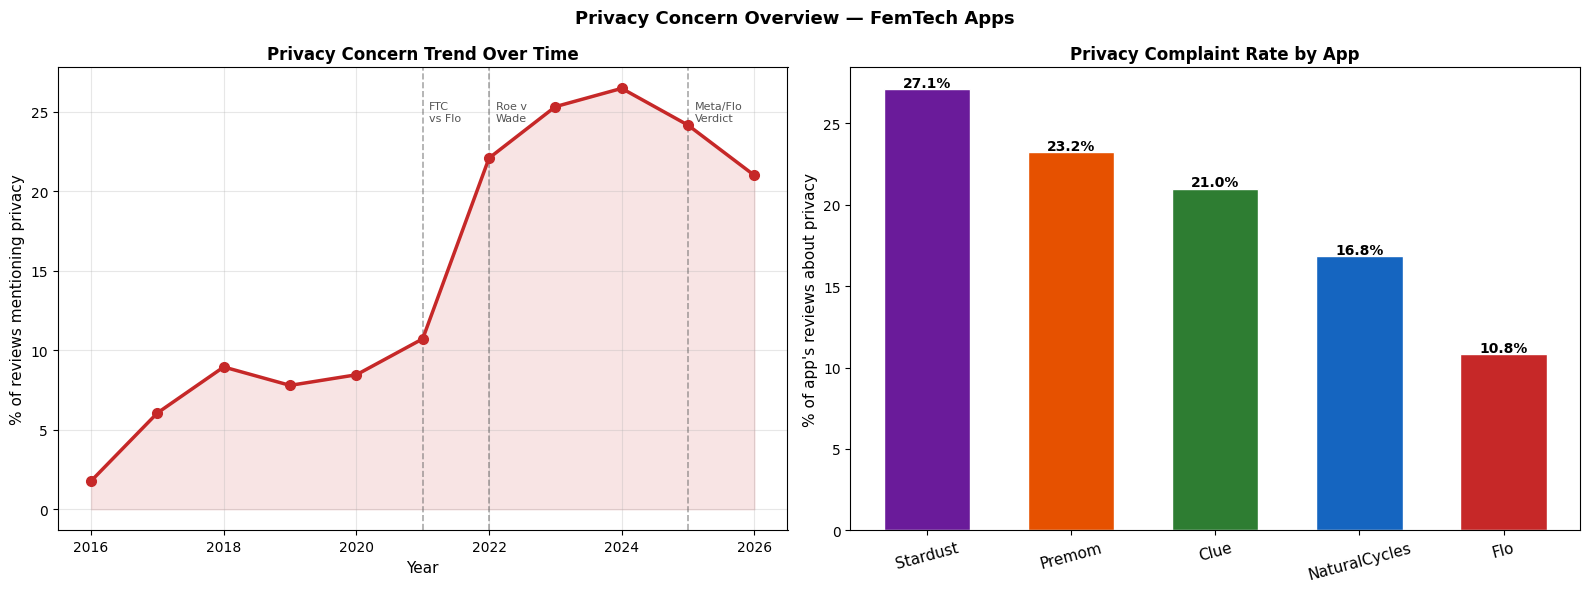

In [62]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: trends by year 
yearly = (df[df["app_name"] != "general"]
          .groupby("year")["is_privacy"]
          .agg(["sum","count"]))
yearly["pct"] = yearly["sum"] / yearly["count"] * 100
yearly = yearly[yearly["count"] > 200]

ax = axes[0]
ax.plot(yearly.index, yearly["pct"], color="#C62828",
        linewidth=2.5, marker="o", markersize=7, zorder=3)
ax.fill_between(yearly.index, yearly["pct"], alpha=0.12, color="#C62828")

events = {2021: "FTC\nvs Flo", 2022: "Roe v\nWade", 2025: "Meta/Flo\nVerdict"}
for yr, label in events.items():
    if yr in yearly.index:
        ax.axvline(yr, color="#555", linestyle="--", alpha=0.5, linewidth=1.2)
        ax.text(yr+0.1, yearly["pct"].max()*0.97, label,
                fontsize=8, color="#555", va="top")

ax.set_xlabel("Year", fontsize=11)
ax.set_ylabel("% of reviews mentioning privacy", fontsize=11)
ax.set_title("Privacy Concern Trend Over Time", fontsize=12, fontweight="bold")
ax.grid(True, alpha=0.3)

# Plot 2: by app
app_p = (df[df["app_name"].isin(APPS)]
         .groupby("app_name")["is_privacy"]
         .agg(["sum","count"]))
app_p["pct"] = app_p["sum"] / app_p["count"] * 100
app_p = app_p.sort_values("pct", ascending=False)

ax2 = axes[1]
colors_b = [APP_COLORS[a] for a in app_p.index]
bars = ax2.bar(range(len(app_p)), app_p["pct"], color=colors_b, edgecolor="white", width=0.6)
ax2.set_xticks(range(len(app_p)))
ax2.set_xticklabels(app_p.index, rotation=15, fontsize=11)
ax2.set_ylabel("% of app's reviews about privacy", fontsize=11)
ax2.set_title("Privacy Complaint Rate by App", fontsize=12, fontweight="bold")
for bar, val in zip(bars, app_p["pct"]):
    ax2.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.15,
             f"{val:.1f}%", ha="center", fontsize=10, fontweight="bold")

plt.suptitle("Privacy Concern Overview — FemTech Apps", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("results/s2_privacy_overview.png", dpi=150, bbox_inches="tight")
plt.show()

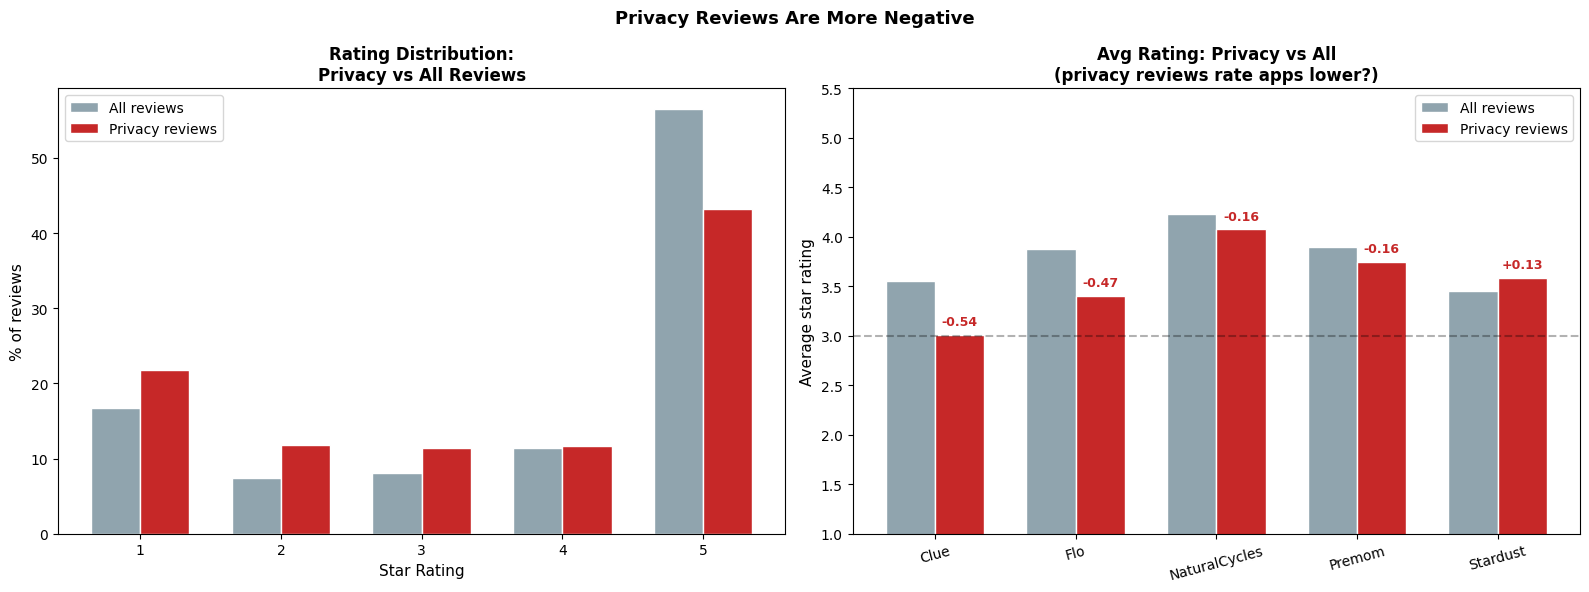

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: ratings distribution
priv_ratings = df[df["is_privacy"]]["rating"].value_counts().sort_index()
norm_ratings  = df[~df["is_privacy"]]["rating"].value_counts().sort_index()
pct_priv = priv_ratings / priv_ratings.sum() * 100
pct_norm = norm_ratings / norm_ratings.sum() * 100

x, w = np.arange(1, 6), 0.35
ax = axes[0]
ax.bar(x-w/2, pct_norm.reindex(x, fill_value=0), w,
       label="All reviews", color="#90A4AE", edgecolor="white")
ax.bar(x+w/2, pct_priv.reindex(x, fill_value=0), w,
       label="Privacy reviews", color="#C62828", edgecolor="white")
ax.set_xlabel("Star Rating", fontsize=11)
ax.set_ylabel("% of reviews", fontsize=11)
ax.set_title("Rating Distribution:\nPrivacy vs All Reviews", fontsize=12, fontweight="bold")
ax.set_xticks(x)
ax.legend(fontsize=10)

# Plot 2: privary vs all
avg_all  = df[df["app_name"].isin(APPS)].groupby("app_name")["rating"].mean()
avg_priv = df[df["is_privacy"] & df["app_name"].isin(APPS)].groupby("app_name")["rating"].mean()
apps_s = sorted(APPS)
x2 = np.arange(len(apps_s))

ax2 = axes[1]
ax2.bar(x2-w/2, [avg_all.get(a,0) for a in apps_s], w,
        label="All reviews", color="#90A4AE", edgecolor="white")
ax2.bar(x2+w/2, [avg_priv.get(a,0) for a in apps_s], w,
        label="Privacy reviews", color="#C62828", edgecolor="white")
ax2.set_xticks(x2)
ax2.set_xticklabels(apps_s, rotation=15, fontsize=10)
ax2.set_ylabel("Average star rating", fontsize=11)
ax2.set_ylim(1, 5.5)
ax2.set_title("Avg Rating: Privacy vs All\n(privacy reviews rate apps lower?)",
              fontsize=12, fontweight="bold")
ax2.legend(fontsize=10)
ax2.axhline(3, color="black", linestyle="--", alpha=0.3)

for i, a in enumerate(apps_s):
    diff = avg_priv.get(a,0) - avg_all.get(a,0)
    ax2.text(i+w/2, avg_priv.get(a,0)+0.1, f"{diff:+.2f}",
             ha="center", fontsize=9, color="#C62828", fontweight="bold")

plt.suptitle("Privacy Reviews Are More Negative", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("results/s2_ratings_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## POLICY SECTION: tbd

In [55]:
# ── Task #5: LLM Privacy Policy Scoring ──────────────────────────────────────
# 6 dimensions, 0-10 each. Based on CHI 2025 femtech taxonomy.

DIMENSIONS = [
    ("data_collection_clarity",
     "How clearly does the policy explain WHAT sensitive health data is collected? (0=vague/hidden, 10=explicit complete list)"),
    ("third_party_disclosure",
     "How transparently does it disclose sharing data with third parties like advertisers or analytics firms? (0=hidden/buried, 10=fully explicit with named parties)"),
    ("user_control",
     "How much control does the user have: right to delete, export, opt-out of sharing? (0=none mentioned, 10=full explicit rights with instructions)"),
    ("data_retention",
     "How clearly does it explain how long sensitive health data is retained? (0=no mention, 10=specific timeframes per data category)"),
    ("legal_basis",
     "How clearly does it state the legal basis for processing sensitive health data (GDPR/CCPA/HIPAA)? (0=none, 10=explicit legal basis per data type)"),
    ("plain_language",
     "How readable is the policy for a non-expert? (0=dense legal jargon only, 10=clear plain language with examples)"),
]

SYSTEM_POLICY = """You are an expert in data privacy law (GDPR, CCPA, HIPAA) specializing in femtech and health apps.
Score privacy policies strictly. A high score requires explicit, specific language — vague promises score low.
Respond ONLY with valid JSON. No extra text."""

def score_one_policy(app_name, policy_text):
    scores = {}
    for dim, question in DIMENSIONS:
        prompt = f"""Analyze this privacy policy from the femtech app '{app_name}'.

Question: {question}

Policy text (first 4000 chars):
{policy_text[:4000]}

Respond ONLY with valid JSON:
{{"score": <integer 0-10>, "reason": "<max 20 words explaining the score>", "evidence": "<direct quote from policy or 'not found'>"}}"""

        result = ask_gpt(prompt, system=SYSTEM_POLICY, max_tokens=200)
        try:
            parsed = json.loads(result)
            scores[dim] = parsed
            print(f"    {dim}: {parsed['score']}/10 — {parsed['reason'][:50]}")
        except:
            print(f"    {dim}: parse error")
            scores[dim] = {"score": 0, "reason": "parse error", "evidence": ""}
        time.sleep(0.5)
    return scores

# Load policies
with open("raw_data/privacy_policies.json") as f:
    POLICIES = json.load(f)

all_policy_scores = {}
for app, text in POLICIES.items():
    if len(text) < 200:
        print(f"Skipping {app} — text too short, paste manually first")
        continue
    print(f"\n{'='*50}")
    print(f"Scoring: {app} ({len(text):,} chars)")
    all_policy_scores[app] = score_one_policy(app, text)

# Save
with open("raw_data/policy_scores.json", "w") as f:
    json.dump(all_policy_scores, f, ensure_ascii=False, indent=2)
print("\nSaved to raw_data/policy_scores.json")



Scoring: Flo (46,514 chars)
    data_collection_clarity: 5/10 — Vague description of data types, lacks a complete 
    third_party_disclosure: 4/10 — Vague about third-party sharing; lacks specific na
    user_control: 9/10 — Explicit rights to delete, access, and withdraw co
    data_retention: 0/10 — No mention of data retention timeframes for sensit
    legal_basis: 5/10 — Legal basis mentioned but lacks specificity for ea
    plain_language: 7/10 — Generally clear language with some technical terms

Scoring: Clue (52,644 chars)
    data_collection_clarity: 8/10 — Explicitly lists types of health data collected.
    third_party_disclosure: 4/10 — Vague about third-party sharing, lacks specific na
    user_control: 7/10 — User rights mentioned but lacks detailed instructi
    data_retention: 0/10 — No specific timeframes for data retention mentione
    legal_basis: 6/10 — Mentions processing health data but lacks specific
    plain_language: 8/10 — Clear language with some technical

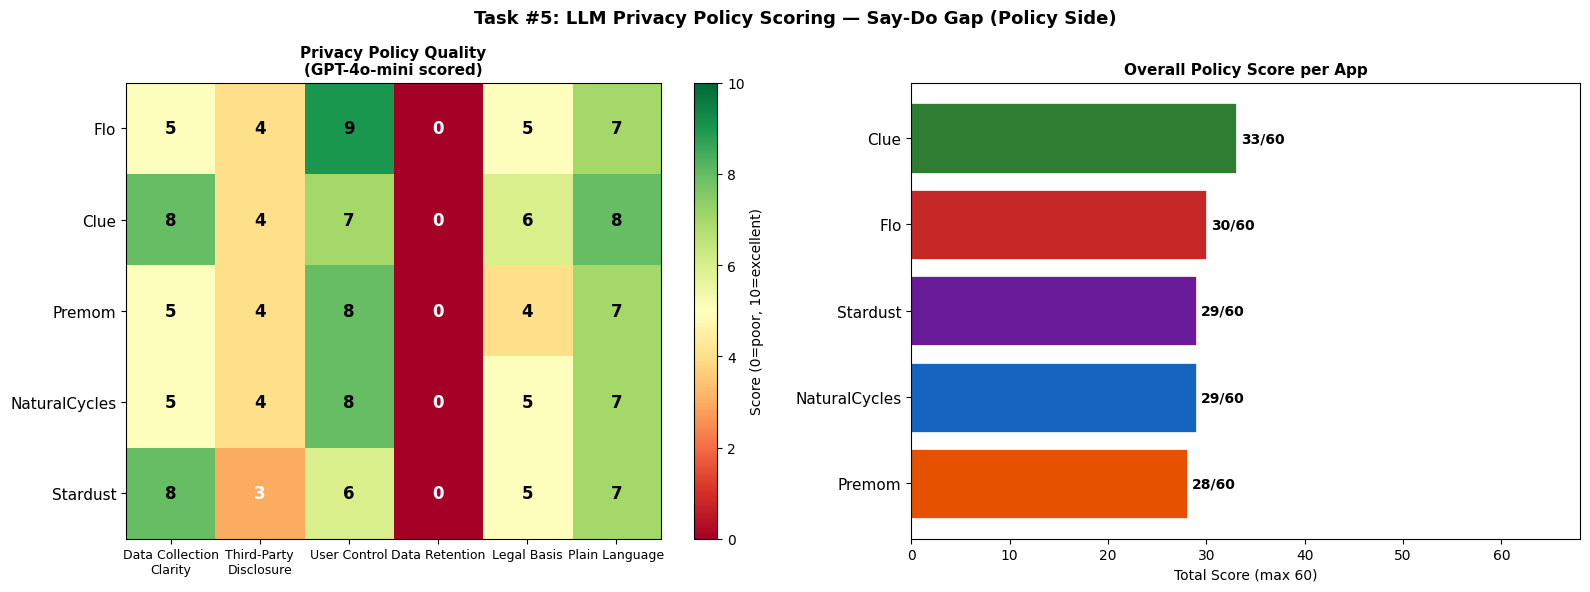


Policy scores:
               Data Collection\nClarity  Third-Party\nDisclosure  User Control  Data Retention  Legal Basis  Plain Language
Flo                                   5                        4             9               0            5               7
Clue                                  8                        4             7               0            6               8
Premom                                5                        4             8               0            4               7
NaturalCycles                         5                        4             8               0            5               7
Stardust                              8                        3             6               0            5               7

Totals (out of 60):
Clue             33
Flo              30
NaturalCycles    29
Stardust         29
Premom           28


In [56]:
# ── Visualize Policy Scores ───────────────────────────────────────────────────
with open("raw_data/policy_scores.json") as f:
    all_policy_scores = json.load(f)

dims = [d for d, _ in DIMENSIONS]
dim_labels = ["Data Collection\nClarity", "Third-Party\nDisclosure",
              "User Control", "Data Retention", "Legal Basis", "Plain Language"]
apps = list(all_policy_scores.keys())
APP_COLORS = {"Flo": "#C62828", "Clue": "#2E7D32", "Premom": "#E65100",
              "NaturalCycles": "#1565C0", "Stardust": "#6A1B9A"}

matrix = [[all_policy_scores[app][d]["score"] for d in dims] for app in apps]
score_df = pd.DataFrame(matrix, index=apps, columns=dim_labels)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Heatmap
ax = axes[0]
im = ax.imshow(score_df.values, cmap="RdYlGn", aspect="auto", vmin=0, vmax=10)
ax.set_xticks(range(len(dim_labels)))
ax.set_xticklabels(dim_labels, fontsize=9)
ax.set_yticks(range(len(apps)))
ax.set_yticklabels(apps, fontsize=11)
for i in range(len(apps)):
    for j in range(len(dim_labels)):
        val = score_df.values[i,j]
        ax.text(j, i, str(val), ha="center", va="center",
                fontsize=12, fontweight="bold",
                color="white" if val < 4 else "black")
plt.colorbar(im, ax=ax, label="Score (0=poor, 10=excellent)")
ax.set_title("Privacy Policy Quality\n(GPT-4o-mini scored)", fontsize=11, fontweight="bold")

# Total bar
ax2 = axes[1]
totals = score_df.sum(axis=1).sort_values()
colors_bar = [APP_COLORS.get(a, "#888") for a in totals.index]
bars = ax2.barh(range(len(totals)), totals.values, color=colors_bar, edgecolor="white", linewidth=0.5)
ax2.set_yticks(range(len(totals)))
ax2.set_yticklabels(totals.index, fontsize=11)
ax2.set_xlabel("Total Score (max 60)", fontsize=10)
ax2.set_xlim(0, 68)
for bar, val in zip(bars, totals.values):
    ax2.text(bar.get_width()+0.5, bar.get_y()+bar.get_height()/2,
             f"{val:.0f}/60", va="center", fontsize=10, fontweight="bold")
ax2.set_title("Overall Policy Score per App", fontsize=11, fontweight="bold")

plt.suptitle("Task #5: LLM Privacy Policy Scoring — Say-Do Gap (Policy Side)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
os.makedirs("results", exist_ok=True)
plt.savefig("results/policy_scores.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nPolicy scores:")
print(score_df.to_string())
print("\nTotals (out of 60):")
print(totals.sort_values(ascending=False).to_string())


## Section 3: LLM Analysis — GPT-4o-mini

In [57]:
df = pd.read_csv("master_dataset_sentiment.csv")
text_col = "review_clean" if "review_clean" in df.columns else "review"

keywords = (
    r"privacy|private|personal data|my data|data sold|sell.?data|share.?data|data.?shar"
    r"|third.?party|third party|facebook|meta|google|adverti"
    r"|encrypt|secure|security|hack|breach|leak|safe|unsafe"
    r"|location|gps|track|tracking|surveillance|monitor"
    r"|delete.*account|delete.*data|export.*data|right.*forget"
    r"|government|law enforcement|subpoena|roe|abortion|warrant"
    r"|switch.*app|switch.*clue|switch.*flo|switched.*to|moving.*to"
    r"|trust|don.t trust|untrustworthy|shady|suspicious|creepy|scary"
    r"|HIPAA|GDPR|CCPA|FTC|regulation|compliance"
)

all_privacy = df[df[text_col].str.contains(keywords, case=False, na=False)].copy()

privacy_df = (
    all_privacy[all_privacy["app_name"] != "general"]
    .groupby("app_name", group_keys=False)
    .apply(lambda x: x.sample(min(2000, len(x)), random_state=42))
    .reset_index(drop=True)
)

print(f"analyzing: {len(privacy_df):,} reviews")
print(f"\nBy app:")
print(privacy_df["app_name"].value_counts().to_string())

analyzing: 9,980 reviews

By app:
app_name
Clue             2000
Flo              2000
Premom           2000
Stardust         2000
NaturalCycles    1980


/var/folders/pw/m0rkh2l51_b0zj4_25qwbjkw0000gp/T/ipykernel_28900/1331655046.py:19: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  all_privacy[all_privacy["app_name"] != "general"]


In [58]:
# ── Batch GPT-4o-mini Analysis ────────────────────────────────────────
import os, json, time
from tqdm import tqdm

SYSTEM_BATCH = """You are a privacy researcher analyzing femtech app reviews.
Return ONLY a valid JSON array, no extra text."""

def analyze_batch(reviews_batch):
    """Send 10 reviews at once, get JSON array back."""
    numbered = "\n".join([f"{i+1}. {r[:300]}" for i, r in enumerate(reviews_batch)])
    prompt = f"""Analyze these {len(reviews_batch)} femtech app reviews for privacy concerns.

{numbered}

Return a JSON array with exactly {len(reviews_batch)} objects, one per review, in order:
[
  {{
    "sentiment": "positive" or "negative" or "neutral",
    "privacy_concern": one of ["data_selling","third_party_sharing","location_tracking","encryption_security","data_retention","account_deletion","government_access","advertising","switching_app","trust_concern","other_privacy","none"],
    "severity": integer 1-5
  }},
  ...
]"""
    for attempt in range(3):
        try:
            r = client.chat.completions.create(
                model=MODEL,
                messages=[
                    {"role": "system", "content": SYSTEM_BATCH},
                    {"role": "user",   "content": prompt}
                ],
                temperature=0.1,
                max_tokens=600,
            )
            text = r.choices[0].message.content.strip()
            # Clean markdown if present
            if "```" in text:
                text = text.split("```")[1].replace("json","").strip()
            parsed = json.loads(text)
            if isinstance(parsed, list) and len(parsed) == len(reviews_batch):
                return parsed
        except Exception as e:
            time.sleep(2 ** attempt)
    # Fallback if parse fails
    return [{"sentiment": None, "privacy_concern": None, "severity": None}] * len(reviews_batch)

# ── Run ────────────────────────────────────────────────────────────────────────
BATCH_SIZE = 20
SAVE_EVERY = 500  # save checkpoint every 500 reviews

texts = privacy_df[text_col].fillna("").tolist()
indices = privacy_df.index.tolist()
apps = privacy_df["app_name"].tolist()
bert_sents = privacy_df["sentiment_label"].tolist() if "sentiment_label" in privacy_df.columns else [""] * len(privacy_df)

results = []
os.makedirs("raw_data", exist_ok=True)
checkpoint_file = "raw_data/llm_checkpoint.json"

# Resume from checkpoint if exists
start_idx = 0
if os.path.exists(checkpoint_file):
    with open(checkpoint_file) as f:
        results = json.load(f)
    start_idx = len(results)
    print(f"Resuming from checkpoint: {start_idx:,} already done")

batches = [texts[i:i+BATCH_SIZE] for i in range(start_idx, len(texts), BATCH_SIZE)]
batch_indices = [indices[i:i+BATCH_SIZE] for i in range(start_idx, len(indices), BATCH_SIZE)]
batch_apps = [apps[i:i+BATCH_SIZE] for i in range(start_idx, len(apps), BATCH_SIZE)]
batch_bert = [bert_sents[i:i+BATCH_SIZE] for i in range(start_idx, len(bert_sents), BATCH_SIZE)]

print(f"Analyzing {len(texts) - start_idx:,} reviews in {len(batches):,} batches...")
print(f"Estimated time: ~{len(batches) // 3} minutes\n")

for b_num, (batch, b_idx, b_app, b_bert) in enumerate(
        tqdm(zip(batches, batch_indices, batch_apps, batch_bert), total=len(batches))):
    
    batch_results = analyze_batch(batch)
    
    for i, res in enumerate(batch_results):
        results.append({
            "original_idx":   b_idx[i],
            "app_name":       b_app[i],
            "bert_sentiment": b_bert[i],
            "text_preview":   batch[i][:100],
            "sentiment":      res.get("sentiment"),
            "privacy_concern":res.get("privacy_concern"),
            "severity":       res.get("severity"),
        })
    
    # Save checkpoint
    if (b_num + 1) % (SAVE_EVERY // BATCH_SIZE) == 0:
        with open(checkpoint_file, "w") as f:
            json.dump(results, f)
    
    time.sleep(0.15)

# Final save
llm_df = pd.DataFrame(results)
llm_df.to_csv("raw_data/llm_sentiment_privacy.csv", index=False)
with open(checkpoint_file, "w") as f:
    json.dump(results, f)

Resuming from checkpoint: 9,980 already done
Analyzing 0 reviews in 0 batches...
Estimated time: ~0 minutes



0it [00:00, ?it/s]


In [64]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# plot 1: top concerns
ax = axes[0]
concern_pct = (concern_df["privacy_concern"].value_counts()
               / len(concern_df) * 100).head(10)
colors_c = plt.cm.Reds_r(np.linspace(0.2, 0.8, len(concern_pct)))
bars = ax.barh(range(len(concern_pct)), concern_pct.values,
               color=colors_c, edgecolor="white")
ax.set_yticks(range(len(concern_pct)))
ax.set_yticklabels(concern_pct.index, fontsize=10)
ax.set_xlabel("% of privacy-concern reviews", fontsize=11)
ax.invert_yaxis()
for bar, val in zip(bars, concern_pct.values):
    ax.text(bar.get_width()+0.3, bar.get_y()+bar.get_height()/2,
            f"{val:.1f}%", va="center", fontsize=9)
ax.set_title("What Privacy Issues Users Mention\n(GPT-4o-mini classified)",
             fontsize=12, fontweight="bold")

# plot 2: severity by concern type
ax2 = axes[1]
sev = (concern_df.groupby("privacy_concern")["severity"]
       .mean().sort_values(ascending=False))
colors_sev = ["#C62828" if v >= 3.5 else
              "#EF5350" if v >= 3.0 else
              "#90A4AE" for v in sev.values]
bars2 = ax2.bar(range(len(sev)), sev.values, color=colors_sev, edgecolor="white")
ax2.set_xticks(range(len(sev)))
ax2.set_xticklabels(sev.index, rotation=35, ha="right", fontsize=9)
ax2.axhline(3, color="#C62828", linestyle="--", alpha=0.5, label="Medium (3/5)")
ax2.set_ylabel("Average Severity (1=low, 5=high)", fontsize=11)
ax2.set_ylim(0, 5.5)
ax2.set_title("Severity of Each Privacy Concern",
              fontsize=12, fontweight="bold")
ax2.legend(fontsize=9)
for bar, val in zip(bars2, sev.values):
    ax2.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.08,
             f"{val:.1f}", ha="center", fontsize=9, fontweight="bold")

plt.suptitle("Section 3: LLM Privacy Analysis — Concern Types & Severity",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("results/s3_llm_concerns.png", dpi=150, bbox_inches="tight")
plt.show()

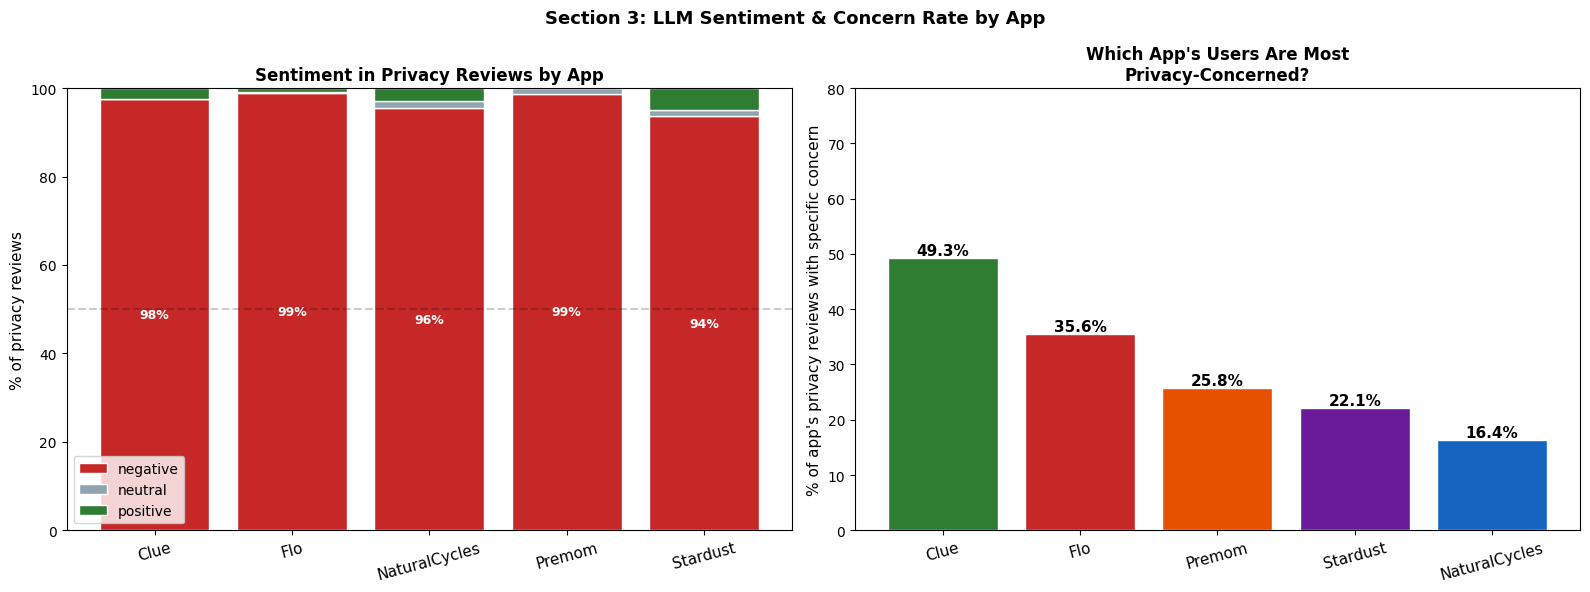

In [65]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# plot 1: stacked sentiment
ax = axes[0]
sent_app = (concern_df.groupby(["app_name","sentiment"])
            .size().unstack(fill_value=0))
sent_pct = sent_app.div(sent_app.sum(axis=1), axis=0) * 100
colors_s = {"negative": "#C62828", "neutral": "#90A4AE", "positive": "#2E7D32"}
bottom = [0]*len(sent_pct)
for sent in ["negative","neutral","positive"]:
    if sent in sent_pct.columns:
        vals = sent_pct[sent].values
        bars = ax.bar(range(len(sent_pct)), vals, bottom=bottom,
                      color=colors_s[sent], label=sent, edgecolor="white")
        for i,(b,v) in enumerate(zip(bottom,vals)):
            if v > 6:
                ax.text(i, b+v/2, f"{v:.0f}%", ha="center", va="center",
                        fontsize=9, color="white", fontweight="bold")
        bottom = [b+v for b,v in zip(bottom,vals)]
ax.set_xticks(range(len(sent_pct)))
ax.set_xticklabels(sent_pct.index, rotation=15, fontsize=11)
ax.set_ylabel("% of privacy reviews", fontsize=11)
ax.set_title("Sentiment in Privacy Reviews by App",
             fontsize=12, fontweight="bold")
ax.legend(fontsize=10)
ax.axhline(50, color="black", linestyle="--", alpha=0.2)

# plot 2: % of users with privacy concern by app
ax2 = axes[1]
total_by_app   = llm_df[llm_df["app_name"].isin(APPS)].groupby("app_name").size()
concern_by_app = concern_df[concern_df["app_name"].isin(APPS)].groupby("app_name").size()
pct_concerned  = (concern_by_app / total_by_app * 100).sort_values(ascending=False)
colors_app = [APP_COLORS.get(a,"#888") for a in pct_concerned.index]
bars = ax2.bar(range(len(pct_concerned)), pct_concerned.values,
               color=colors_app, edgecolor="white")
ax2.set_xticks(range(len(pct_concerned)))
ax2.set_xticklabels(pct_concerned.index, rotation=15, fontsize=11)
ax2.set_ylabel("% of app's privacy reviews with specific concern", fontsize=11)
ax2.set_ylim(0, 80)
ax2.set_title("Which App's Users Are Most\nPrivacy-Concerned?",
              fontsize=12, fontweight="bold")
for bar, val in zip(bars, pct_concerned.values):
    ax2.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
             f"{val:.1f}%", ha="center", fontsize=11, fontweight="bold")

plt.suptitle("Section 3: LLM Sentiment & Concern Rate by App",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("results/s3_llm_sentiment_app.png", dpi=150, bbox_inches="tight")
plt.show()

In [66]:
fig, axes = plt.subplots(1, 5, figsize=(22, 6), sharey=False)

for i, app in enumerate(APPS):
    ax = axes[i]
    app_data = concern_df[concern_df["app_name"] == app]
    if len(app_data) == 0:
        ax.set_visible(False)
        continue
    top = (app_data["privacy_concern"].value_counts()
           / len(app_data) * 100).head(6)
    colors_app_c = plt.cm.Reds_r(np.linspace(0.2, 0.75, len(top)))
    bars = ax.barh(range(len(top)), top.values,
                   color=colors_app_c, edgecolor="white")
    ax.set_yticks(range(len(top)))
    ax.set_yticklabels(top.index, fontsize=8)
    ax.invert_yaxis()
    ax.set_title(app, fontsize=11, fontweight="bold",
                 color=APP_COLORS[app])
    ax.set_xlabel("% of reviews", fontsize=8)
    for bar, val in zip(bars, top.values):
        ax.text(bar.get_width()+0.3, bar.get_y()+bar.get_height()/2,
                f"{val:.0f}%", va="center", fontsize=8)

plt.suptitle("Top Privacy Concerns per App (GPT-4o-mini)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("results/s3_concerns_per_app.png", dpi=150, bbox_inches="tight")
plt.show()

## Section 4: Scandal Reaction +- 2 Months Window

In [67]:
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df = df.dropna(subset=["date"])
df["year_month"] = df["date"].dt.to_period("M")

# key events 
if "sentiment_score" in df.columns:
    df["sent_numeric"] = df["sentiment_score"]
elif "sentiment_label" in df.columns:
    sent_map = {"positive": 1, "neutral": 0, "negative": -1,
                "1 star": -1, "2 stars": -0.5, "3 stars": 0,
                "4 stars": 0.5, "5 stars": 1}
    df["sent_numeric"] = df["sentiment_label"].map(sent_map)
else:
    df["sent_numeric"] = df["rating"].map({1:-1,2:-0.5,3:0,4:0.5,5:1})

EVENTS = {
    "FTC Action\nvs Flo":     pd.Timestamp("2021-01-13"),
    "Roe v Wade\nOverturn":   pd.Timestamp("2022-06-24"),
    "Meta/Flo\nJury Verdict": pd.Timestamp("2025-08-15"),
    "Premom\nFTC Fine":       pd.Timestamp("2023-05-17"),
}

print("Events defined:")
for name, date in EVENTS.items():
    n = len(df[(df["date"] >= date - pd.Timedelta(days=60)) &
               (df["date"] <= date + pd.Timedelta(days=60))])
    print(f"  {name.replace(chr(10),' ')}: {date.date()} — {n:,} reviews in ±2mo window")

Events defined:
  FTC Action vs Flo: 2021-01-13 — 3,659 reviews in ±2mo window
  Roe v Wade Overturn: 2022-06-24 — 2,555 reviews in ±2mo window
  Meta/Flo Jury Verdict: 2025-08-15 — 5,124 reviews in ±2mo window
  Premom FTC Fine: 2023-05-17 — 1,835 reviews in ±2mo window


In [68]:
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
axes_flat = axes.flatten()

for idx, (event_name, event_date) in enumerate(EVENTS.items()):
    ax = axes_flat[idx]
    
    window_start = event_date - pd.Timedelta(days=70)
    window_end   = event_date + pd.Timedelta(days=70)
    
    window_df = df[(df["date"] >= window_start) & (df["date"] <= window_end)].copy()
    window_df["week"] = window_df["date"].dt.to_period("W")
    
    # weekly sentinment
    weekly = (window_df.groupby("week")
              .agg(avg_sent=("sent_numeric","mean"),
                   count=("sent_numeric","count"))
              .reset_index())
    weekly["week_date"] = weekly["week"].dt.start_time
    weekly["days_from_event"] = (weekly["week_date"] - event_date).dt.days
    
    # 70 days
    weekly = weekly[weekly["days_from_event"].abs() <= 70]
    
    if len(weekly) < 3:
        ax.set_title(f"{event_name} — insufficient data", fontsize=10)
        continue
    
    ax2_twin = ax.twinx()
    ax2_twin.bar(weekly["days_from_event"], weekly["count"],
                 width=6, alpha=0.2, color="#90A4AE", zorder=1)
    ax2_twin.set_ylabel("Review count", fontsize=9, color="#90A4AE")
    ax2_twin.tick_params(axis="y", labelcolor="#90A4AE")
    
    # Line: sentiment
    ax.plot(weekly["days_from_event"], weekly["avg_sent"],
            color="#C62828", linewidth=2, marker="o", markersize=5, zorder=3)
    ax.axhline(0, color="black", linewidth=0.8, alpha=0.4)
    ax.axvline(0, color="#C62828", linewidth=2, linestyle="--",
               alpha=0.8, label="Event date")
    ax.axvspan(-60, 0, alpha=0.04, color="blue", label="Before")
    ax.axvspan(0,  60, alpha=0.04, color="red",  label="After")
    
    # avg before after
    before = weekly[weekly["days_from_event"] < 0]["avg_sent"].mean()
    after  = weekly[weekly["days_from_event"] > 0]["avg_sent"].mean()
    delta  = after - before
    
    ax.set_xlabel("Days from event", fontsize=10)
    ax.set_ylabel("Avg sentiment", fontsize=10)
    ax.set_title(f"{event_name}", fontsize=11, fontweight="bold")
    ax.set_xlim(-75, 75)
    ax.grid(True, alpha=0.3)
    
    ax.text(0.02, 0.05,
            f"Before: {before:.3f}\nAfter:  {after:.3f}\nΔ = {delta:+.3f}",
            transform=ax.transAxes, fontsize=9,
            bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8))
    ax.legend(fontsize=8, loc="upper right")

plt.suptitle("Section 4: User Sentiment Reaction to Privacy Scandals (±2 months)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("results/s4_scandal_reaction.png", dpi=150, bbox_inches="tight")
plt.show()

In [69]:
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
axes_flat = axes.flatten()

privacy_df_time = df[df["is_privacy"]].copy()

for idx, (event_name, event_date) in enumerate(EVENTS.items()):
    ax = axes_flat[idx]
    
    window_df = privacy_df_time[
        (privacy_df_time["date"] >= event_date - pd.Timedelta(days=70)) &
        (privacy_df_time["date"] <= event_date + pd.Timedelta(days=70))
    ].copy()
    
    weekly = (window_df.groupby(window_df["date"].dt.to_period("W"))
              .agg(avg_sent=("sent_numeric","mean"),
                   count=("sent_numeric","count"))
              .reset_index())
    weekly["week_date"] = weekly["date"].dt.start_time
    weekly["days_from_event"] = (weekly["week_date"] - event_date).dt.days
    weekly = weekly[weekly["days_from_event"].abs() <= 70]
    
    if len(weekly) < 3:
        ax.set_title(f"{event_name} — insufficient data", fontsize=10)
        continue
    
    ax.plot(weekly["days_from_event"], weekly["avg_sent"],
            color="#C62828", linewidth=2.5, marker="o", markersize=6)
    ax.axhline(0, color="black", linewidth=0.8, alpha=0.4)
    ax.axvline(0, color="#C62828", linewidth=2, linestyle="--", alpha=0.8)
    ax.axvspan(-60, 0, alpha=0.04, color="blue")
    ax.axvspan(0,  60, alpha=0.04, color="red")
    
    before = weekly[weekly["days_from_event"] < 0]["avg_sent"].mean()
    after  = weekly[weekly["days_from_event"] > 0]["avg_sent"].mean()
    delta  = after - before
    
    ax.set_xlabel("Days from event", fontsize=10)
    ax.set_ylabel("Avg sentiment (privacy reviews only)", fontsize=10)
    ax.set_title(f"{event_name} — privacy reviews only", fontsize=11, fontweight="bold")
    ax.set_xlim(-75, 75)
    ax.grid(True, alpha=0.3)
    ax.text(0.02, 0.05,
            f"Before: {before:.3f}\nAfter:  {after:.3f}\nΔ = {delta:+.3f}",
            transform=ax.transAxes, fontsize=9,
            bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8))

plt.suptitle("Section 4b: Privacy Reviews — Sentiment Reaction to Scandals",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("results/s4_scandal_privacy_only.png", dpi=150, bbox_inches="tight")
plt.show()

## Section 5: Google Trends — Privacy Search Interest

In [78]:
trends = pd.read_csv("google-trends1.csv")
trends = trends.rename(columns={"Time": "date"})
trends["date"] = pd.to_datetime(trends["date"], errors="coerce")
trends = trends.dropna(subset=["date"])
for col in trends.columns[1:]:
    trends[col] = pd.to_numeric(trends[col], errors="coerce").fillna(0)

print("Columns:", list(trends.columns))
print(f"Date range: {trends['date'].min().date()} → {trends['date'].max().date()}")

Columns: ['date', 'delete flo', 'flo privacy', 'clue privacy', 'delete clue', 'stardust privacy', 'premom privacy', 'natural cycles privacy', 'period tracker apps privacy']
Date range: 2015-12-01 → 2026-06-01


In [79]:
fig, ax = plt.subplots(figsize=(16, 7))

def get_trend_color(col):
    col = col.lower().strip()
    if col == "flo privacy":                   return "#C62828", 2.5
    if col == "clue privacy":                  return "#2E7D32", 2.5
    if col == "premom privacy":                return "#E65100", 2.5
    if col == "natural cycles privacy":        return "#1565C0", 2.5
    if col == "stardust privacy":              return "#6A1B9A", 2.5
    if col == "delete flo":                    return "#EF9A9A", 1.8
    if col == "delete clue":                   return "#81C784", 1.8
    if col == "period tracker apps privacy":   return "#FF8F00", 2.2
    return "#BDBDBD", 1.0

for col in trends.columns[1:]:
    color, lw = get_trend_color(col)
    if trends[col].max() == 0:
        continue
    ax.plot(trends["date"], trends[col],
            label=col, color=color, linewidth=lw, alpha=1.0)

events_v = {
    "2021-01": "FTC vs Flo",
    "2022-06": "Roe v Wade",
    "2023-05": "Premom FTC",
    "2025-08": "Meta/Flo Verdict",
}
ymax = trends.iloc[:, 1:].max().max()
for date_str, label in events_v.items():
    d = pd.Timestamp(date_str)
    ax.axvline(d, color="#555", linestyle="--", alpha=0.6, linewidth=1.2)
    ax.text(d, ymax * 0.97, label, rotation=90,
            fontsize=8, color="#333", va="top", ha="right")

ax.set_xlabel("Date", fontsize=11)
ax.set_ylabel("Google Trends Index (0–100)", fontsize=11)
ax.set_title("Google Trends: Privacy Search Interest in FemTech Apps",
             fontsize=12, fontweight="bold")
ax.legend(fontsize=8, loc="upper left", ncol=2)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("results/s5_trends_overview.png", dpi=150, bbox_inches="tight")
plt.show()

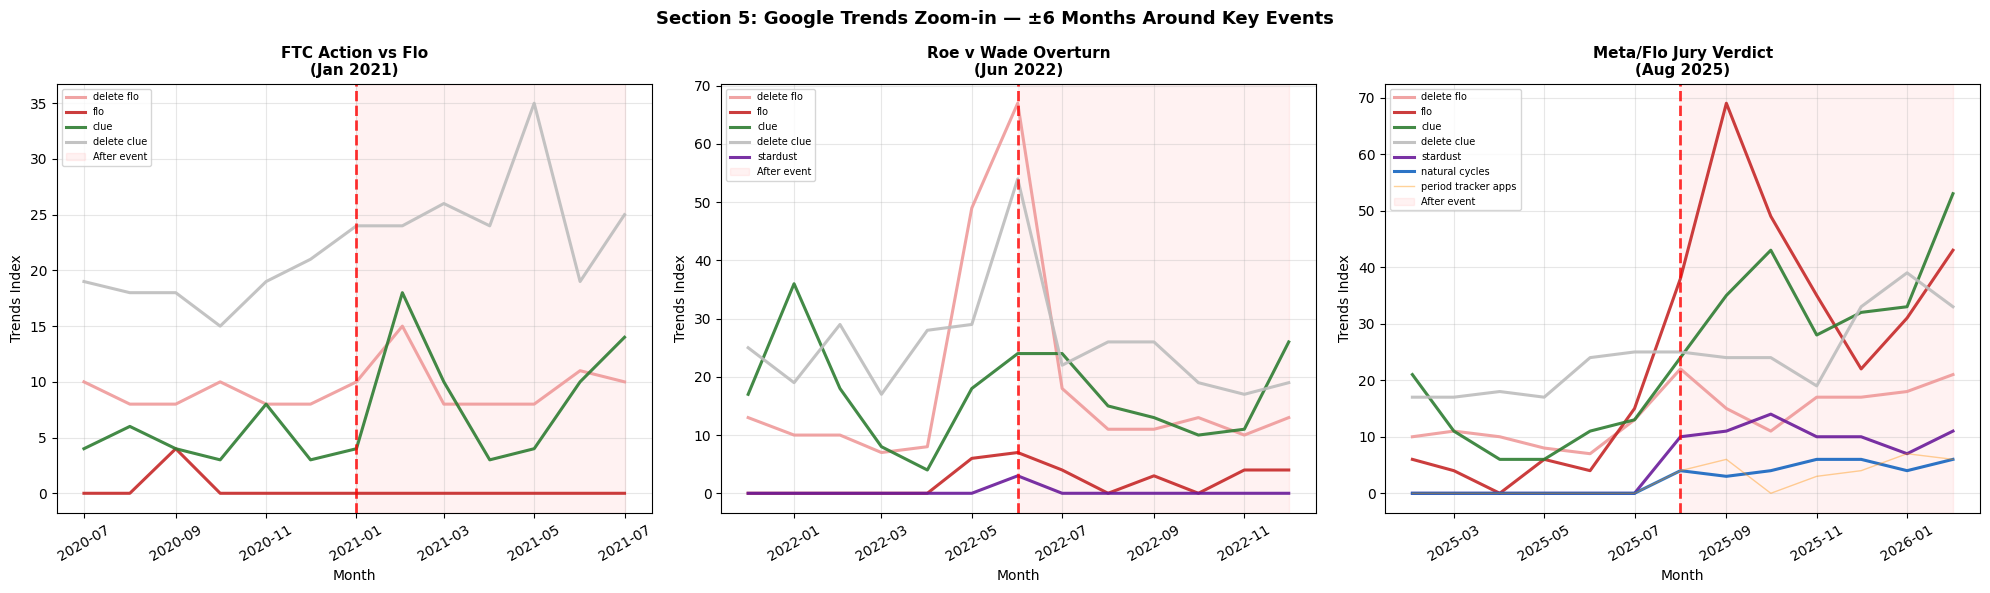

In [80]:
ZOOM_EVENTS = {
    "FTC Action vs Flo\n(Jan 2021)":       "2021-01",
    "Roe v Wade Overturn\n(Jun 2022)":     "2022-06",
    "Meta/Flo Jury Verdict\n(Aug 2025)":   "2025-08",
}

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for idx, (event_label, event_month) in enumerate(ZOOM_EVENTS.items()):
    ax = axes[idx]
    event_date = pd.Timestamp(event_month)
    start = event_date - pd.DateOffset(months=6)
    end   = event_date + pd.DateOffset(months=6)
    
    zoom = trends[(trends["date"] >= start) & (trends["date"] <= end)]
    
    for col in trends.columns[1:]:
        color = next((v for k,v in TREND_COLORS.items()
                      if k.lower() in col.lower()), "#BDBDBD")
        lw = 2.2 if any(k in col.lower() for k in ["flo","clue","premom","natural","stardust"]) else 1.0
        alpha = 0.9 if lw > 1 else 0.4
        if zoom[col].max() > 0:
            ax.plot(zoom["date"], zoom[col], label=col.replace(" privacy",""),
                    color=color, linewidth=lw, alpha=alpha)
    
    ax.axvline(event_date, color="red", linewidth=2, linestyle="--", alpha=0.8)
    ax.axvspan(event_date, end, alpha=0.05, color="red", label="After event")
    ax.set_title(event_label, fontsize=11, fontweight="bold")
    ax.set_xlabel("Month", fontsize=10)
    ax.set_ylabel("Trends Index", fontsize=10)
    ax.legend(fontsize=7, loc="upper left")
    ax.grid(True, alpha=0.3)
    ax.tick_params(axis="x", rotation=30)

plt.suptitle("Section 5: Google Trends Zoom-in — ±6 Months Around Key Events",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("results/s5_trends_zoomin.png", dpi=150, bbox_inches="tight")
plt.show()

SUMMARY TABLE: Key Privacy Findings per App
              Total Reviews % Privacy Reviews Avg Rating (all) Avg Rating (priv) LLM % Negative % Concerned        Top Concern Avg Severity
App                                                                                                                                        
Flo                  25,152             10.8%             3.87              3.40          47.5%       35.6%        advertising         3.91
Clue                 27,107             21.0%             3.55              3.01          63.2%       49.3%        advertising         3.94
Premom               11,639             23.2%             3.90              3.74          34.9%       25.8%  location_tracking         4.25
NaturalCycles        10,014             16.8%             4.23              4.07          23.6%       16.4%      trust_concern         3.78
Stardust             11,820             27.1%             3.45              3.58          44.1%       22.1%   accoun

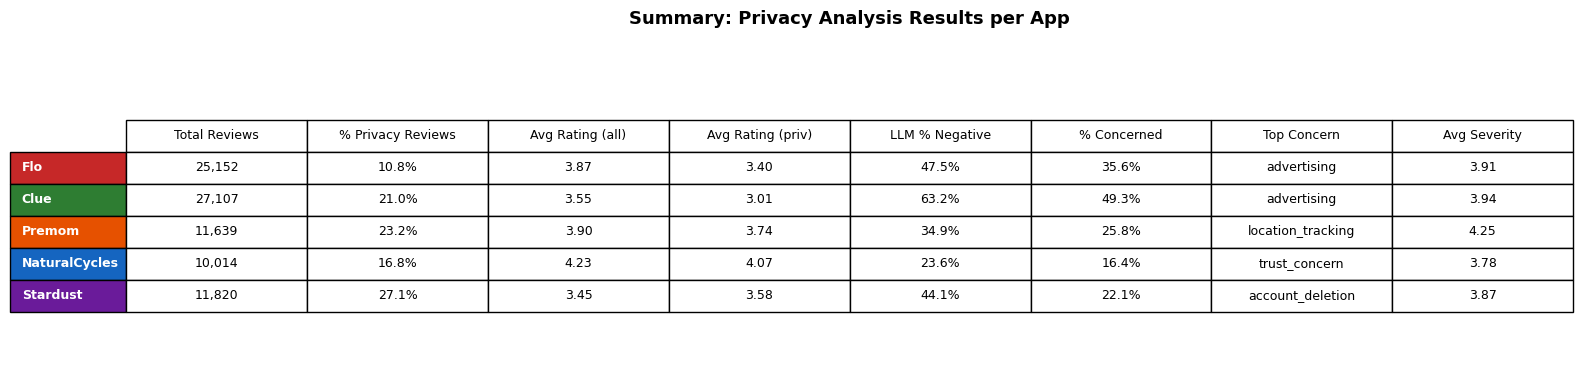

In [ ]:
summary = []
for app in APPS:
    app_df       = df[df["app_name"] == app]
    app_priv     = app_df[app_df["is_privacy"]]
    app_llm      = llm_df[llm_df["app_name"] == app]
    app_concern  = concern_df[concern_df["app_name"] == app]
    
    total_reviews     = len(app_df)
    pct_privacy       = len(app_priv) / total_reviews * 100 if total_reviews > 0 else 0
    avg_rating_all    = app_df["rating"].mean()
    avg_rating_priv   = app_priv["rating"].mean() if len(app_priv) > 0 else None
    
    llm_neg_pct       = (app_llm["sentiment"] == "negative").mean() * 100 if len(app_llm) > 0 else None
    pct_concerned     = len(app_concern) / len(app_llm) * 100 if len(app_llm) > 0 else None
    top_concern       = app_concern["privacy_concern"].mode()[0] if len(app_concern) > 0 else "—"
    avg_severity      = app_concern["severity"].mean() if len(app_concern) > 0 else None
    
    summary.append({
        "App":              app,
        "Total Reviews":    f"{total_reviews:,}",
        "% Privacy Reviews":f"{pct_privacy:.1f}%",
        "Avg Rating (all)": f"{avg_rating_all:.2f}",
        "Avg Rating (priv)":f"{avg_rating_priv:.2f}" if avg_rating_priv else "—",
        "LLM % Negative":   f"{llm_neg_pct:.1f}%" if llm_neg_pct else "—",
        "% Concerned":      f"{pct_concerned:.1f}%" if pct_concerned else "—",
        "Top Concern":      top_concern,
        "Avg Severity":     f"{avg_severity:.2f}" if avg_severity else "—",
    })

summary_df = pd.DataFrame(summary).set_index("App")
print("=" * 90)
print("SUMMARY TABLE: Key Privacy Findings per App")
print("=" * 90)
print(summary_df.to_string())
print("=" * 90)
ì
fig, ax = plt.subplots(figsize=(16, 4))
ax.axis("off")
table = ax.table(
    cellText=summary_df.values,
    colLabels=summary_df.columns,
    rowLabels=summary_df.index,
    cellLoc="center", loc="center",
)
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1.2, 1.8)

for i, app in enumerate(APPS):
    color = APP_COLORS[app]
    table[(i+1, -1)].set_facecolor(color)
    table[(i+1, -1)].set_text_props(color="white", fontweight="bold")

ax.set_title("Summary: Privacy Analysis Results per App",
             fontsize=13, fontweight="bold", pad=20)
plt.tight_layout()
plt.savefig("results/s6_summary_table.png", dpi=150, bbox_inches="tight")
plt.show()

## Section 7: Privacy Policy Analysis (GPT-4o-mini Scored)

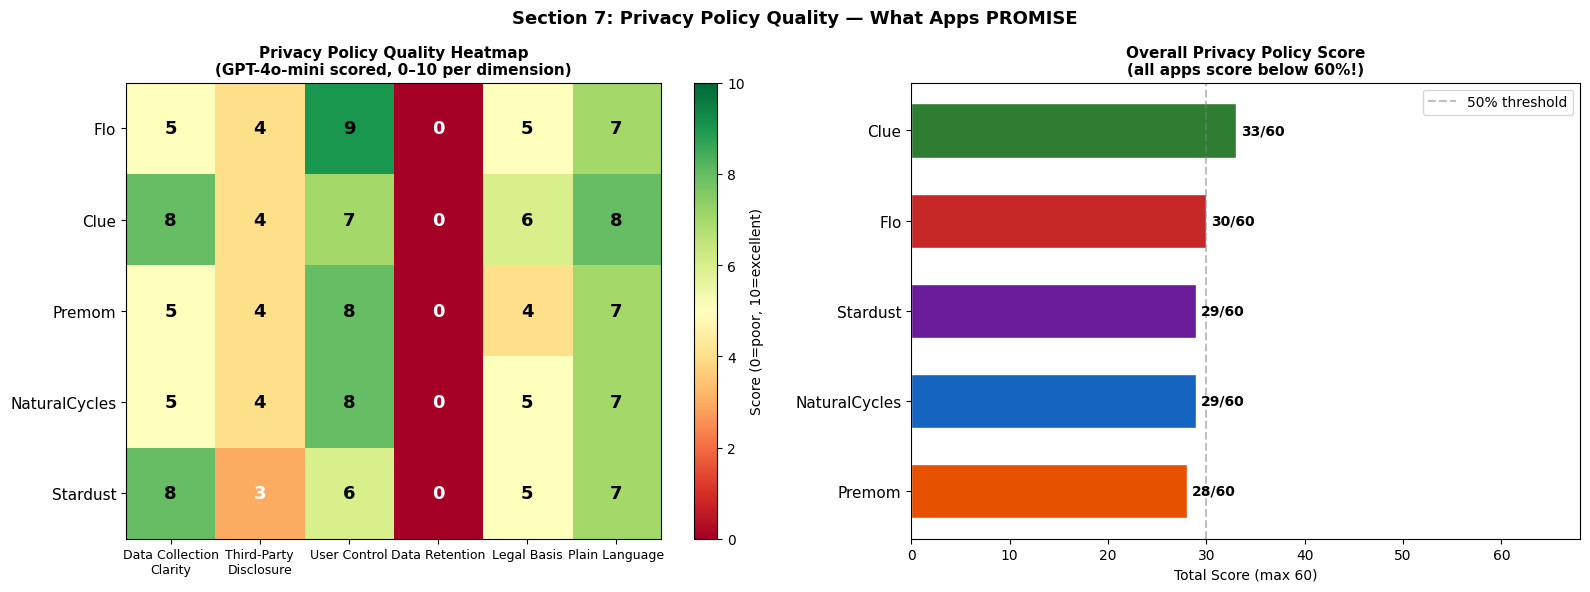

               Data Collection\nClarity  Third-Party\nDisclosure  User Control  Data Retention  Legal Basis  Plain Language
Flo                                   5                        4             9               0            5               7
Clue                                  8                        4             7               0            6               8
Premom                                5                        4             8               0            4               7
NaturalCycles                         5                        4             8               0            5               7
Stardust                              8                        3             6               0            5               7


In [82]:
import json
import numpy as np
import matplotlib.pyplot as plt

with open("raw_data/policy_scores.json") as f:
    policy_scores_raw = json.load(f)

DIMS = [
    "data_collection_clarity",
    "third_party_disclosure",
    "user_control",
    "data_retention",
    "legal_basis",
    "plain_language",
]
DIM_LABELS = [
    "Data Collection\nClarity",
    "Third-Party\nDisclosure",
    "User Control",
    "Data Retention",
    "Legal Basis",
    "Plain Language",
]
APP_COLORS = {"Flo":"#C62828","Clue":"#2E7D32","Premom":"#E65100",
              "NaturalCycles":"#1565C0","Stardust":"#6A1B9A"}
apps = list(policy_scores_raw.keys())
matrix = [[policy_scores_raw[a][d]["score"] for d in DIMS] for a in apps]
score_df = pd.DataFrame(matrix, index=apps, columns=DIM_LABELS)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Heatmap
ax = axes[0]
im = ax.imshow(score_df.values, cmap="RdYlGn", aspect="auto", vmin=0, vmax=10)
ax.set_xticks(range(len(DIM_LABELS)))
ax.set_xticklabels(DIM_LABELS, fontsize=9)
ax.set_yticks(range(len(apps)))
ax.set_yticklabels(apps, fontsize=11)
for i in range(len(apps)):
    for j in range(len(DIM_LABELS)):
        val = score_df.values[i,j]
        ax.text(j, i, str(int(val)), ha="center", va="center",
                fontsize=13, fontweight="bold",
                color="white" if val < 4 else "black")
plt.colorbar(im, ax=ax, label="Score (0=poor, 10=excellent)")
ax.set_title("Privacy Policy Quality Heatmap\n(GPT-4o-mini scored, 0–10 per dimension)",
             fontsize=11, fontweight="bold")

# Total bar
ax2 = axes[1]
totals = score_df.sum(axis=1).sort_values()
colors_bar = [APP_COLORS[a] for a in totals.index]
bars = ax2.barh(range(len(totals)), totals.values,
                color=colors_bar, edgecolor="white", height=0.6)
ax2.set_yticks(range(len(totals)))
ax2.set_yticklabels(totals.index, fontsize=11)
ax2.set_xlabel("Total Score (max 60)", fontsize=10)
ax2.set_xlim(0, 68)
ax2.axvline(30, color="gray", linestyle="--", alpha=0.5, label="50% threshold")
for bar, val in zip(bars, totals.values):
    ax2.text(bar.get_width()+0.5, bar.get_y()+bar.get_height()/2,
             f"{int(val)}/60", va="center", fontsize=10, fontweight="bold")
ax2.set_title("Overall Privacy Policy Score\n(all apps score below 60%!)",
              fontsize=11, fontweight="bold")
ax2.legend()

plt.suptitle("Section 7: Privacy Policy Quality — What Apps PROMISE",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("results/s7_policy_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

print(score_df.to_string())

In [83]:
from matplotlib.patches import FancyArrowPatch
import matplotlib.patches as mpatches

fig, ax = plt.subplots(figsize=(9, 9), subplot_kw=dict(polar=True))

N = len(DIMS)
angles = np.linspace(0, 2*np.pi, N, endpoint=False).tolist()
angles += angles[:1]

for app in apps:
    vals = [policy_scores_raw[app][d]["score"] for d in DIMS]
    vals += vals[:1]
    ax.plot(angles, vals, color=APP_COLORS[app], linewidth=2, label=app)
    ax.fill(angles, vals, color=APP_COLORS[app], alpha=0.08)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(DIM_LABELS, fontsize=10)
ax.set_ylim(0, 10)
ax.set_yticks([2, 4, 6, 8, 10])
ax.set_yticklabels(["2","4","6","8","10"], fontsize=8)
ax.set_title("Privacy Policy Dimensions — Radar Chart\n(CHI 2025 methodology)",
             fontsize=12, fontweight="bold", pad=20)
ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.1), fontsize=10)
ax.grid(True, alpha=0.4)

plt.tight_layout()
plt.savefig("results/s7_policy_radar.png", dpi=150, bbox_inches="tight")
plt.show()

## Section 8: Say-Do Gap Index — The Core Finding

In [84]:
# Policy score (SAY) — normalising 0-100
policy_totals = {}
for app in apps:
    total = sum(policy_scores_raw[app][d]["score"] for d in DIMS)
    policy_totals[app] = round(total / 60 * 100, 1)

# User negativity (DO) — from LLM analysis
user_neg = {}
for app in apps:
    app_llm = llm_df[llm_df["app_name"] == app]
    if len(app_llm) == 0:
        continue
    pct_neg  = (app_llm["sentiment"] == "negative").mean() * 100
    app_con  = concern_df[concern_df["app_name"] == app]
    avg_sev  = app_con["severity"].mean() * 20 if len(app_con) > 0 else 50
    user_neg[app] = round(pct_neg * 0.6 + avg_sev * 0.4, 1)

# Say-Do Gap = how much policy is better than reality
gap_data = []
for app in apps:
    if app not in policy_totals or app not in user_neg:
        continue
    say  = policy_totals[app]             # high = good policy
    do   = 100 - user_neg[app]            # high = users are happy
    gap  = say - do                       # high = app over-promises
    gap_data.append({"App": app, "Policy Score (SAY)": say,
                     "User Trust (DO)": do, "Say-Do Gap": gap})

gap_df = pd.DataFrame(gap_data).set_index("App")
print("Say-Do Gap Index:")
print(gap_df.round(1).to_string())
print(f"\nMost over-promising: {gap_df['Say-Do Gap'].idxmax()} (+{gap_df['Say-Do Gap'].max():.1f})")
print(f"Most honest:         {gap_df['Say-Do Gap'].idxmin()} ({gap_df['Say-Do Gap'].min():.1f})")

Say-Do Gap Index:
               Policy Score (SAY)  User Trust (DO)  Say-Do Gap
App                                                           
Flo                          50.0             40.2         9.8
Clue                         55.0             30.5        24.5
Premom                       46.7             45.0         1.7
NaturalCycles                48.3             55.6        -7.3
Stardust                     48.3             42.6         5.7

Most over-promising: Clue (+24.5)
Most honest:         NaturalCycles (-7.3)


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Scatter: SAY vs DO
ax = axes[0]
for app in gap_df.index:
    x = gap_df.loc[app, "Policy Score (SAY)"]
    y = gap_df.loc[app, "User Trust (DO)"]
    c = APP_COLORS[app]
    ax.scatter(x, y, s=250, color=c, zorder=3, edgecolors="white", linewidth=1.5)
    ax.annotate(app, (x, y), textcoords="offset points",
                xytext=(10, 4), fontsize=10, fontweight="bold", color=c)

ax.plot([0,100],[0,100], "k--", alpha=0.25, linewidth=1.2)
ax.fill_between([0,100],[0,100],[100,100], alpha=0.04,
                color="red", label="Over-promises (SAY > DO)")
ax.fill_between([0,100],[0,0],[0,100], alpha=0.04,
                color="green", label="Under-promises")
ax.set_xlabel("Policy Score — what app SAYS (0–100)", fontsize=11)
ax.set_ylabel("User Trust — what users PERCEIVE (0–100)", fontsize=11)
ax.set_xlim(0, 100); ax.set_ylim(0, 100)
ax.set_title("Say-Do Gap: Policy Promises vs User Reality",
             fontsize=12, fontweight="bold")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
ax.text(5, 92, "Apps above diagonal\nover-promise privacy",
        fontsize=9, color="red", alpha=0.7)

# Bar: gap magnitude
ax2 = axes[1]
gap_sorted = gap_df["Say-Do Gap"].sort_values(ascending=False)
colors_gap = [APP_COLORS[a] for a in gap_sorted.index]
bars = ax2.bar(range(len(gap_sorted)), gap_sorted.values,
               color=colors_gap, edgecolor="white", width=0.6)
ax2.axhline(0, color="black", linewidth=1.2)
ax2.set_xticks(range(len(gap_sorted)))
ax2.set_xticklabels(gap_sorted.index, rotation=15, fontsize=11)
ax2.set_ylabel("Say-Do Gap Score\n(+ = over-promises, − = under-promises)",
               fontsize=10)
ax2.set_title("Say-Do Gap Index per App\n(THE core finding)",
              fontsize=12, fontweight="bold")
for bar, val in zip(bars, gap_sorted.values):
    offset = 0.5 if val >= 0 else -2.5
    ax2.text(bar.get_x()+bar.get_width()/2, bar.get_height()+offset,
             f"{val:+.1f}", ha="center", fontsize=11, fontweight="bold")

plt.suptitle("Section 8: Say-Do Gap Index — FemTech Privacy\n"
             "Do apps deliver what they promise?",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("results/s8_say_do_gap.png", dpi=150, bbox_inches="tight")
plt.show()

## Section 9: BERTopic — Topic Modeling Results

In [96]:
topics_df = pd.read_csv("raw_data/topics_labeled_en.csv")
topic_col = "topic_label"
print(f"Loaded {topics_df[topic_col].nunique()} topics")
print(topics_df[topic_col].value_counts().head(20).to_string())

Loaded 96 topics
topic_label
0_cycle_love_body_moon                              6313
3_clue_plus_pay_ads                                 3449
4_accurate_love_app_best                            3321
5_period_cycle_helps_track                          1343
6_open_crashing_crashes_wont                        1341
7_subscription_ads_pay_free                         1207
8_natural_control_birth_hormonal                    1146
9_android_laggy_slow_load                           1042
10_flo_better_best_period                           1010
12_thermometer_temperature_temp_bluetooth            843
13_cancel_subscription_refund_charged                771
14_sign_account_log_login                            733
16_period_log_day_edit                               661
17_women_woman_trans_girls                           652
18_accurate_reliable_easy_accuracy                   484
19_helpful_helps_alot_lot                            483
20_ovulation_premom_helped_track                     481
21

In [97]:
topics_df = pd.read_csv("raw_data/topics_labeled_en.csv")
all_topics = topics_df["topic_label"].value_counts()
print(f"All {len(all_topics)} topics:\n")
print(all_topics.to_string())

All 96 topics:

topic_label
0_cycle_love_body_moon                              6313
3_clue_plus_pay_ads                                 3449
4_accurate_love_app_best                            3321
5_period_cycle_helps_track                          1343
6_open_crashing_crashes_wont                        1341
7_subscription_ads_pay_free                         1207
8_natural_control_birth_hormonal                    1146
9_android_laggy_slow_load                           1042
10_flo_better_best_period                           1010
12_thermometer_temperature_temp_bluetooth            843
13_cancel_subscription_refund_charged                771
14_sign_account_log_login                            733
16_period_log_day_edit                               661
17_women_woman_trans_girls                           652
18_accurate_reliable_easy_accuracy                   484
19_helpful_helps_alot_lot                            483
20_ovulation_premom_helped_track                     481
21_

In [ ]:
fig, ax = plt.subplots(figsize=(11, 7))

priv_stats = []
for raw_label, clean_label in PRIVACY_TOPICS.items():
    sub = topics_df[topics_df["topic_label"] == raw_label]
    if len(sub) == 0:
        continue
    neg_pct = (sub["sentiment_label"] == "negative").mean() * 100
    count   = len(sub)
    priv_stats.append({"label": clean_label, "neg_pct": neg_pct, "count": count})

priv_stats = sorted(priv_stats, key=lambda x: x["neg_pct"])
labels   = [d["label"]   for d in priv_stats]
neg_vals = [d["neg_pct"] for d in priv_stats]
counts   = [d["count"]   for d in priv_stats]

avg_neg = (topics_df[~topics_df["is_privacy_topic"]]["sentiment_label"] == "negative").mean() * 100

# Lollipop
for i, (label, val, cnt) in enumerate(zip(labels, neg_vals, counts)):
    ax.plot([avg_neg, val], [i, i], color="#BDBDBD", linewidth=2, zorder=1)
    ax.scatter(val, i, s=cnt/1.5, color="#C62828", zorder=3, edgecolors="white", linewidth=1.5)
    ax.text(val + 1.5, i, f"{val:.0f}%", va="center", fontsize=11, fontweight="bold", color="#C62828")

ax.axvline(avg_neg, color="#455A64", linewidth=2, linestyle="--", alpha=0.7,
           label=f"Avg non-privacy topics: {avg_neg:.0f}%")

ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels, fontsize=11)
ax.set_xlabel("% Negative Sentiment", fontsize=12)
ax.set_xlim(0, 115)
ax.set_title("Privacy Topics Are Highly Negative\n(dot size = number of reviews)",
             fontsize=13, fontweight="bold")
ax.legend(fontsize=10, loc="lower right")
ax.grid(axis="x", alpha=0.3)

for i, cnt in enumerate(counts):
    ax.text(neg_vals[i], i - 0.35, f"n={cnt:,}", ha="center", fontsize=8, color="#888")

plt.tight_layout()
plt.savefig("results/s9_privacy_lollipop.png", dpi=150, bbox_inches="tight")
plt.show()

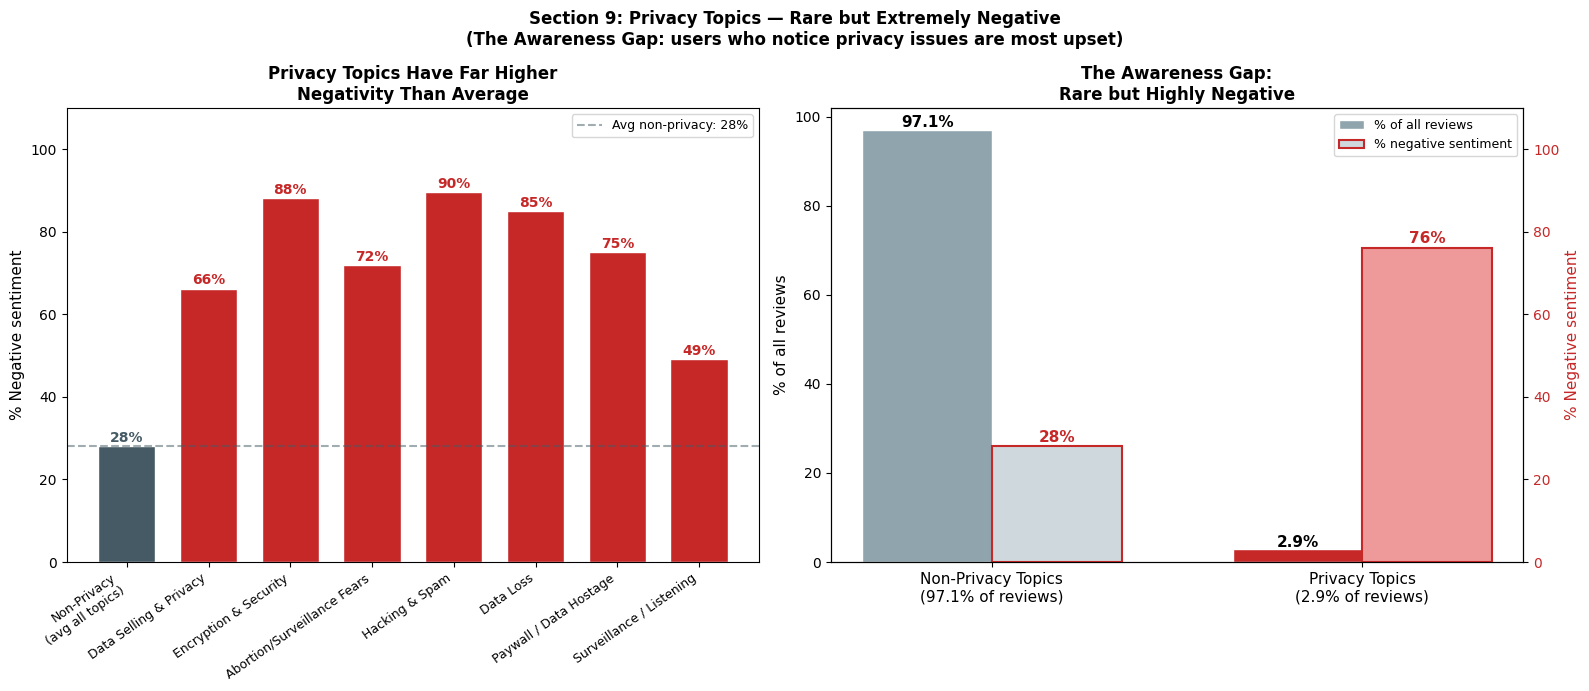

In [100]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# График 1: Privacy topics — negativity rate vs обычные темы
ax = axes[0]

# Средний % негативных для НЕ-privacy топиков
non_priv = topics_df[~topics_df["is_privacy_topic"]]
non_priv_neg = (non_priv["sentiment_label"] == "negative").mean() * 100

# % негативных для каждого privacy топика
priv_neg_rates = {}
for raw_label, clean_label in PRIVACY_TOPICS.items():
    sub = topics_df[topics_df["topic_label"] == raw_label]
    if len(sub) > 0:
        priv_neg_rates[clean_label] = (sub["sentiment_label"] == "negative").mean() * 100

all_rates = {"Non-Privacy\n(avg all topics)": non_priv_neg}
all_rates.update(priv_neg_rates)

colors_neg = ["#455A64"] + ["#C62828"] * len(priv_neg_rates)
bars = ax.bar(range(len(all_rates)), list(all_rates.values()),
              color=colors_neg, edgecolor="white", width=0.7)
ax.set_xticks(range(len(all_rates)))
ax.set_xticklabels(list(all_rates.keys()), rotation=35, ha="right", fontsize=9)
ax.set_ylabel("% Negative sentiment", fontsize=11)
ax.set_ylim(0, 110)
ax.axhline(non_priv_neg, color="#455A64", linestyle="--",
           alpha=0.5, linewidth=1.5, label=f"Avg non-privacy: {non_priv_neg:.0f}%")
ax.set_title("Privacy Topics Have Far Higher\nNegativity Than Average",
             fontsize=12, fontweight="bold")
ax.legend(fontsize=9)
for bar, val in zip(bars, all_rates.values()):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+1,
            f"{val:.0f}%", ha="center", fontsize=10, fontweight="bold",
            color="#C62828" if val > non_priv_neg else "#455A64")

# График 2: "Iceberg" — объём vs severity
ax2 = axes[1]
categories = ["Non-Privacy Topics\n(97.1% of reviews)", 
              "Privacy Topics\n(2.9% of reviews)"]
volumes    = [97.1, 2.9]
neg_rates  = [non_priv_neg, 
              (topics_df[topics_df["is_privacy_topic"]]["sentiment_label"]=="negative").mean()*100]

x = np.arange(2)
w = 0.35
b1 = ax2.bar(x - w/2, volumes, w, color=["#90A4AE","#C62828"],
             edgecolor="white", label="% of all reviews")
ax2_twin = ax2.twinx()
b2 = ax2_twin.bar(x + w/2, neg_rates, w, color=["#CFD8DC","#EF9A9A"],
                  edgecolor="#C62828", linewidth=1.5, label="% negative sentiment")
ax2_twin.set_ylabel("% Negative sentiment", fontsize=11, color="#C62828")
ax2_twin.tick_params(axis="y", labelcolor="#C62828")
ax2_twin.set_ylim(0, 110)

ax2.set_xticks(x)
ax2.set_xticklabels(categories, fontsize=11)
ax2.set_ylabel("% of all reviews", fontsize=11)
ax2.set_title("The Awareness Gap:\nRare but Highly Negative",
              fontsize=12, fontweight="bold")

for bar, val in zip(b1, volumes):
    ax2.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
             f"{val:.1f}%", ha="center", fontsize=11, fontweight="bold")
for bar, val in zip(b2, neg_rates):
    ax2_twin.text(bar.get_x()+bar.get_width()/2, bar.get_height()+1,
                  f"{val:.0f}%", ha="center", fontsize=11, fontweight="bold", color="#C62828")

lines1, labels1 = ax2.get_legend_handles_labels()
lines2, labels2 = ax2_twin.get_legend_handles_labels()
ax2.legend(lines1+lines2, labels1+labels2, fontsize=9, loc="upper right")

plt.suptitle("Section 9: Privacy Topics — Rare but Extremely Negative\n"
             "(The Awareness Gap: users who notice privacy issues are most upset)",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig("results/s9_awareness_gap.png", dpi=150, bbox_inches="tight")
plt.show()